# Phase B — Individual Implementation
## Conservative LSTM with JAX

**Format:** individual, at home. Implement, train, evaluate, and reflect.

**Prerequisite:** the plan your group wrote in Phase A (`A1_Phase_A_Group_Exercise.ipynb`).

<a id='0'></a>
## 0. Environment setup

Install dependencies if you don't have them yet.

In [1]:
# Uncomment if needed (e.g. a fresh environment or Colab)
%pip install -q "jax[cpu]" flax optax matplotlib
    
import jax
import jax.numpy as jnp
import flax.linen as nn
import optax
import numpy as np
import matplotlib.pyplot as plt
import time

print("JAX version:", jax.__version__)
print("Devices    :", jax.devices())

Note: you may need to restart the kernel to use updated packages.


JAX version: 0.6.2
Devices    : [CpuDevice(id=0)]


<a id='1'></a>
## 1. Introduction to JAX and Flax

JAX is a numerical computing library built around a **functional** programming style. Its syntax is close to NumPy, with three key additions:

| Function | What it does |
|---|---|
| `jax.grad` | Automatic differentiation (exact gradients of any Python function) |
| `jax.jit` | Just-in-time compilation (XLA) → much faster execution |
| `jax.vmap` | Automatic vectorization over a batch axis |

Random numbers use **explicit keys** (`PRNGKey`) instead of a global seed — the same key always gives the same numbers, which makes your code fully reproducible. Neural networks are built with **Flax** (`flax.linen`, imported as `nn`), a layer on top of JAX for trainable models.

Two things to keep in mind:
- JAX functions should be **pure** (no side effects) so that `jit`/`grad` work correctly.
- JAX arrays are **immutable**: you don't modify them in place, you return new ones.

Run the demo below to see all three capabilities in action.

In [2]:
# Mini-demo of JAX's three key capabilities

# (a) Automatic differentiation
f = lambda x: x ** 3 + 2 * x
df = jax.grad(f)                # derivative: 3x^2 + 2
print("f'(2) =", df(2.0), "(expected 14.0)")

# (b) Explicit random keys -> reproducibility
key = jax.random.PRNGKey(0)
k1, k2 = jax.random.split(key)
print("Reproducible sample:", jax.random.normal(k1, (3,)))

# (c) JIT + vmap
g = jax.jit(jax.vmap(f))        # applies f to a whole vector, compiled
print("g([1,2,3]) =", g(jnp.array([1., 2., 3.])))

f'(2) = 14.0 (expected 14.0)


Reproducible sample: [ 1.0040143 -0.9063372 -0.7481722]
g([1,2,3]) = [ 3. 12. 33.]


### Flax basics for recurrent models

- A `nn.Module` describes the *computation*, not the state. You create parameters with `model.init(key, dummy_input)` (returns a `params` pytree), then run the network with `model.apply(params, x)` — `params` is always passed explicitly.
- For recurrence, Flax provides `nn.LSTMCell` (one timestep) and `nn.RNN` (unrolls a cell over a whole sequence). You'll use both below.

### Optax for optimization

```python
optimizer = optax.adam(learning_rate=1e-2)
opt_state = optimizer.init(params)

loss, grads = jax.value_and_grad(loss_fn)(params, batch)
updates, opt_state = optimizer.update(grads, opt_state, params)
params = optax.apply_updates(params, updates)
```

Wrapping this whole step in `@jax.jit` compiles it once and reuses the compiled version on every call — this is what makes JAX training loops fast.

A simple example is often enough to illustrate the Flax programming model before introducing recurrence. The following network learns a basic regression problem using a small multilayer perceptron.

In [3]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax


# ---------------------------------------------------------
# 1. Define a simple neural network
# ---------------------------------------------------------

class SimpleMLP(nn.Module):
    hidden_size: int = 32

    # @nn.compact is a decorator in Flax that tells the framework:
    # “The layers used inside this method should be created automatically 
    # the first time the method is called.”
    # It is the most common way to define Flax models.

    @nn.compact
    def __call__(self, x):
        x = nn.Dense(self.hidden_size)(x)
        x = nn.relu(x)
        x = nn.Dense(1)(x)
        return x

# ---------------------------------------------------------
# 2. Create a synthetic regression dataset
# ---------------------------------------------------------

key = jax.random.PRNGKey(0)
key, data_key, init_key = jax.random.split(key, 3)
x_train = jax.random.normal(data_key, shape=(128, 4))
y_train = (
    2.0 * x_train[:, 0]
    - 1.5 * x_train[:, 1]
    + 0.5 * x_train[:, 2]
    + 0.2
)
y_train = y_train[:, None]

# ---------------------------------------------------------
# 3. Create the model and initialize its parameters
# ---------------------------------------------------------

model = SimpleMLP(hidden_size=16)
dummy_input = jnp.ones((1, 4))
params = model.init(init_key, dummy_input)

# ---------------------------------------------------------
# 4. Define the loss function
# ---------------------------------------------------------

def loss_fn(params, x, y):
    predictions = model.apply(params, x)
    loss = jnp.mean((predictions - y) ** 2)
    return loss

# ---------------------------------------------------------
# 5. Create the optimizer
# ---------------------------------------------------------

optimizer = optax.adam(learning_rate=1e-3)
opt_state = optimizer.init(params)

# ---------------------------------------------------------
# 6. Define one training step
# ---------------------------------------------------------

@jax.jit
def train_step(params, opt_state, x, y):
    loss, gradients = jax.value_and_grad(loss_fn)(
        params,
        x,
        y
    )
    updates, opt_state = optimizer.update(
        gradients,
        opt_state,
        params
    )
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

# ---------------------------------------------------------
# 7. Train the model
# ---------------------------------------------------------

num_epochs = 1000

for epoch in range(num_epochs):
    params, opt_state, loss = train_step(
        params,
        opt_state,
        x_train,
        y_train
    )
    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Loss: {float(loss):.6f}")

# ---------------------------------------------------------
# 8. Evaluate the trained model
# ---------------------------------------------------------

predictions = model.apply(params, x_train)
final_loss = jnp.mean(
    (predictions - y_train) ** 2
)
print(f"Final loss: {float(final_loss):.6f}")


# ---------------------------------------------------------
# 9. Test the model with new samples
# ---------------------------------------------------------

x_test = jnp.array([
    [1.0, 2.0, 3.0, 4.0],
    [-1.0, 0.5, 2.0, 1.0]
])
predicted_values = model.apply(params, x_test)
true_values = (
    2.0 * x_test[:, 0]
    - 1.5 * x_test[:, 1]
    + 0.5 * x_test[:, 2]
    + 0.2
)

print("\nPredictions:")
print(predicted_values.squeeze())

print("\nTrue values:")
print(true_values)

Epoch    0 | Loss: 5.076825
Epoch  100 | Loss: 2.333333
Epoch  200 | Loss: 0.558173
Epoch  300 | Loss: 0.102863
Epoch  400 | Loss: 0.051410
Epoch  500 | Loss: 0.036595
Epoch  600 | Loss: 0.029150
Epoch  700 | Loss: 0.024714
Epoch  800 | Loss: 0.022067
Epoch  900 | Loss: 0.019799


Final loss: 0.017727



Predictions:
[ 0.640568  -1.6374569]

True values:
[ 0.7  -1.55]


<a id='2'></a>
## 2. Scientific background (recap)

Many physical systems obey **conservation laws** (mass, energy, charge, momentum, ...). A conventional neural network trained only to minimize prediction error has no notion of these laws.

Phase A (§2) asked you to compare four ways of incorporating the conservation law and to choose one for your group's plan. This notebook has you implement **two** models: the **baseline** (§5, Option 1 — direct prediction, no physical structure) and **your model** (§6 — whichever of Options 2/3/4 your group chose), then compare them. This is one instance of **physics-informed machine learning**: known structure shrinks the space of functions the network can represent, so a well-chosen architecture can be both physically valid *and* need less data to generalize well.

<a id='3'></a>
## 3. The scenario (recap)

| Symbol | Meaning | Observed? |
|---|---|---|
| `m(t)` | Water mass (volume) in the reservoir | yes |
| `r(t)` | Inflow | yes |
| `q(t)` | Controlled outflow | yes |
| `c(t)` | Hidden consumption | **no** |

$$ m(t+1) = m(t) + r(t) - q(t) - c(t) $$

As in Phase A §1, `c(t)` depends on temperature, hour of day, day of year, and its own small random noise; it is the only unobserved term in the mass balance.

Models will only ever see `x(t) = [m(t), r(t), q(t), temp(t), hour(t), day_year(t)]` as input (matching the variables Phase A identified as driving `c(t)`). The target for training is `m(t+1)`.

<a id='4'></a>
## 4. Task 5.1 — Generate synthetic sequential data

Simulate `N` independent sequences of length `T` (e.g. `N=400`, `T=480` hourly steps ≈ 20 days).

**Design notes / hints:**
- **Inflow / outflow.** The simplest valid design samples `r(t)` and `q(t)` i.i.d. from a fixed range at every timestep (e.g. `r(t) ~ U[2.0, 3.5]`, `q(t) ~ U[1.0, 2.0]`) — they don't need to be autocorrelated or seasonal, since they're always fully observed anyway.
- **Temperature.** Give it a daily cycle plus per-sequence and per-step noise, e.g.
  `temp(t) = 20 + 8·sin(2π(hour(t) − 6)/24) + offset_seq + noise(t)`, where `offset_seq` is drawn once per sequence and `noise(t)` independently at every step.
- **Day of year.** A sequence spans a small window of days (e.g. `T=480` hours ≈ 20 days), so `day_year(t)` is close to constant within a sequence but differs across sequences — draw one starting day per sequence (e.g. `U[0, 365]`) and increment it as `t` advances. Normalize to `[0, 1]` for the network input, same as `hour_norm`.
- **Hidden consumption `c(t)`.** Build it from a base level, a temperature term, and a daily usage profile, then clip to non-negative:

  ```
  hour_profile(t) = 0.5 · (1 + sin(2π(hour(t) − 8)/24))   # peaks around midday/evening
  c_raw(t)        = c0 + α·(temp(t) − mean(temp)) + β·hour_profile(t) + noise_c(t)
  c(t)            = max(0, c_raw(t))                       # consumption can't be negative
  ```

  (e.g. `c0=1.0`, `α=0.05`, `β=1.2`, small-amplitude `noise_c`). Note it's the **clipping**, not the formula itself, that enforces non-negativity. (You could also make `c0`/`α`/`β` depend on `day_year(t)` — e.g. a seasonal component — but a constant base level is enough to complete the task.)
- Roll the mass forward: pick `m(0)` (e.g. `100 + U[0,10]`), then apply `m(t+1) = m(t) + r(t) - q(t) - c(t)` step by step to build the whole sequence.
- Store `X = [m, r, q, temp, hour_norm, day_year_norm]` (that feature order), `Y = m(t+1)`, and `C` (true hidden consumption, diagnostics only).

### 4.0 Configuration and random keys

Every setting of the notebook lives in one `CONFIG` dictionary, so the two models and every experiment read the same values and nothing is hard-coded twice.

JAX has no global random state: each random call takes an explicit **key**, and the same key always gives the same numbers. Two keys are derived from the base seed **112358**:

- `data_key = fold_in(PRNGKey(seed), 0)` generates all the data. The main data and its cold-spell copy (4.3) use this same key, so they share every random draw and differ only in temperature.
- `run_key(name, seed)` gives each training run its own key, by folding a number computed from the run's name into the seed. The number comes from `zlib.crc32`, which is the same in every session (Python's `hash()` of a string changes between sessions). A run's key therefore depends only on its name and the seed, never on the order in which cells are executed, and two runs never share a key.

Each training run is cached in `results/` as one `.npz` file (section 7), so re-running the notebook does not retrain. Delete the folder after changing any code.

In [4]:
import os, zlib

CONFIG = {
    "seed": 112358,
    "n_seq": 450, "T": 480,
    "n_train": 300, "n_val": 50, "n_test": 100,
    "hidden_size": 32, "learning_rate": 1e-2, "clip_norm": 1.0,
    "epochs": 300, "batch_size": 32,
    "mu_grid": [0.01, 0.1, 1.0],            # penalty weights on delta (8E.1)
    "n_train_grid": [25, 50, 100, 200],     # training-set sizes (8E.2)
    "temp_shift": -15.0,                    # cold-spell test set (4.3)
    "use_cache": True,
}


def run_key(name, seed=CONFIG["seed"]):
    """PRNG key of one training run.

    name : str, the run's name, e.g. "baseline_s112358"
    seed : int, the base seed
    Returns a JAX key that depends only on (seed, name).
    """
    # crc32 is stable across sessions, unlike hash(); % 2**31 keeps it a valid int32
    return jax.random.fold_in(jax.random.PRNGKey(seed), zlib.crc32(name.encode()) % 2**31)


# All the data (main and cold-spell bundles) comes from this one key
data_key = jax.random.fold_in(jax.random.PRNGKey(CONFIG["seed"]), 0)

os.makedirs("results", exist_ok=True)   # cache of training runs (section 7)

for k, v in CONFIG.items():
    print(f"{k:14s} {v}")
print(f"\nsplit: {CONFIG['n_train']} train + {CONFIG['n_val']} val + {CONFIG['n_test']} test "
      f"= {CONFIG['n_train'] + CONFIG['n_val'] + CONFIG['n_test']} sequences")
print("results/ exists:", os.path.isdir("results"))

assert CONFIG["n_train"] + CONFIG["n_val"] + CONFIG["n_test"] == CONFIG["n_seq"]
assert os.path.isdir("results")


seed           112358
n_seq          450
T              480
n_train        300
n_val          50
n_test         100
hidden_size    32
learning_rate  0.01
clip_norm      1.0
epochs         300
batch_size     32
mu_grid        [0.01, 0.1, 1.0]
n_train_grid   [25, 50, 100, 200]
temp_shift     -15.0
use_cache      True

split: 300 train + 50 val + 100 test = 450 sequences
results/ exists: True


### 4.1 The data generator

`generate_data` simulates `n_seq` independent reservoirs over `T` hourly steps, following the design notes above. Its key is split into **8 sub-keys**, one per random quantity, so no key is ever reused.

- **Time:** each sequence starts at a random hour `h0` and day `d0`; `hour_norm = hour/24` and `day_year_norm = day_year/365` lie in [0, 1).
- **Flows:** `r ~ U[2.35, 3.85]` and `q ~ U[1.0, 2.0]`, i.i.d. per step. The inflow is a little higher than the template's example: with `U[2.0, 3.5]` the reservoir loses about 0.35 per step on average and its volume becomes negative within a sequence. With this range the mean net flow `r − q − c` is close to zero.
- **Temperature:** daily cycle + per-sequence offset + per-step noise, plus `temp_shift` (0 here; −15 °C for the cold-spell test set of 4.3).
- **Consumption:** `c = max(0, 1.0 + 0.05·(temp − 20) + 1.2·hour_profile + noise_c)`. The temperature reference is the constant 20 (the mean of the formula without shift), so a cold spell really lowers `c`. The `max(0, ·)` clipping is what keeps `c ≥ 0`.
- **Mass:** `m(0) = 150 + U[0, 10]`; then `m(t+1) = m(0) + cumsum(r − q − c)` applies the balance at every step, and `m(t)` is the same series shifted by one step.

Outputs: `X = [m, r, q, temp, hour_norm, day_year_norm]` (n_seq, T, 6), the target `Y = m(t+1)` (n_seq, T), and the true consumption `C` (n_seq, T), kept **only for diagnostics** after training.

In [5]:
def generate_data(key, n_seq=450, T=480, temp_shift=0.0):
    """Generate n_seq sequences of length T for the water-reservoir system.

    key        : JAX PRNG key (split into 8 sub-keys, one per random quantity)
    n_seq, T   : number of sequences and hourly steps per sequence
    temp_shift : constant added to the temperature (0 = normal, -15 = cold spell)

    Returns
    -------
    X : (n_seq, T, 6) float32 -> [m, r, q, temp, hour_norm, day_year_norm]
    Y : (n_seq, T)    float32 -> m(t+1)
    C : (n_seq, T)    float32 -> true hidden consumption (diagnostics only)
    """
    k_h0, k_d0, k_r, k_q, k_off, k_tn, k_c, k_m0 = jax.random.split(key, 8)
    t = jnp.arange(T)

    # Time of day and day of year: random start per sequence, then advance hourly
    h0 = jax.random.randint(k_h0, (n_seq, 1), 0, 24)
    hour = ((h0 + t) % 24).astype(jnp.float32)                            # (n_seq, T)
    d0 = jax.random.uniform(k_d0, (n_seq, 1), minval=0.0, maxval=365.0)
    day_year = (d0 + t / 24.0) % 365.0                                   # (n_seq, T)

    # Observed flows, i.i.d. per step
    r = jax.random.uniform(k_r, (n_seq, T), minval=2.35, maxval=3.85)
    q = jax.random.uniform(k_q, (n_seq, T), minval=1.0, maxval=2.0)

    # Temperature: daily cycle + per-sequence offset + per-step noise (+ optional shift)
    offset_seq = jax.random.normal(k_off, (n_seq, 1))
    temp = (20.0 + temp_shift + 8.0 * jnp.sin(2 * jnp.pi * (hour - 6) / 24)
            + offset_seq + jax.random.normal(k_tn, (n_seq, T)))

    # Hidden consumption; reference temperature fixed at 20 so a shift changes c
    hour_profile = 0.5 * (1 + jnp.sin(2 * jnp.pi * (hour - 8) / 24))
    noise_c = 0.1 * jax.random.normal(k_c, (n_seq, T))
    c = jnp.maximum(0.0, 1.0 + 0.05 * (temp - 20.0) + 1.2 * hour_profile + noise_c)

    # Mass balance rolled forward: Y = m(t+1), m(t) = [m(0), Y(0), ..., Y(T-2)]
    m0 = 150.0 + 10.0 * jax.random.uniform(k_m0, (n_seq, 1))
    Y = m0 + jnp.cumsum(r - q - c, axis=1)
    m = jnp.concatenate([m0, Y[:, :-1]], axis=1)

    X = jnp.stack([m, r, q, temp, hour / 24.0, day_year / 365.0], axis=-1)
    return X.astype(jnp.float32), Y.astype(jnp.float32), c.astype(jnp.float32)


X, Y, C = generate_data(data_key, CONFIG["n_seq"], CONFIG["T"])

m, r, q = X[..., 0], X[..., 1], X[..., 2]
balance_err = float(jnp.max(jnp.abs(Y - (m + r - q - C))))
X_again, _, _ = generate_data(data_key, CONFIG["n_seq"], CONFIG["T"])
X_other, _, _ = generate_data(jax.random.PRNGKey(0), CONFIG["n_seq"], CONFIG["T"])

print("X:", X.shape, " Y:", Y.shape, " C:", C.shape)
print(f"min c = {float(C.min()):.3f}   min m = {float(m.min()):.2f}   max m = {float(m.max()):.2f}")
print(f"hour_norm in [{float(X[..., 4].min()):.3f}, {float(X[..., 4].max()):.3f}]   "
      f"day_year_norm in [{float(X[..., 5].min()):.6f}, {float(X[..., 5].max()):.6f}]")
print(f"max |Y - (m + r - q - c)| = {balance_err:.2e}")

assert X.shape == (450, 480, 6) and Y.shape == (450, 480) and C.shape == (450, 480)
assert bool(jnp.all(C >= 0)) and bool(jnp.all(m > 0))
assert bool(jnp.all((X[..., 4] >= 0) & (X[..., 4] < 1)))
assert bool(jnp.all((X[..., 5] >= 0) & (X[..., 5] < 1)))
assert not (jnp.isnan(X).any() or jnp.isnan(Y).any() or jnp.isnan(C).any())
assert balance_err < 1e-3
assert bool(jnp.all(Y[:, :-1] == X[:, 1:, 0]))      # m(t+1) of one step = m of the next
assert bool(jnp.all(X == X_again))                  # same key -> same data
assert not bool(jnp.all(X == X_other))              # another key -> different data


X: (450, 480, 6)  Y: (450, 480)  C: (450, 480)
min c = 0.151   min m = 80.33   max m = 250.34
hour_norm in [0.000, 0.958]   day_year_norm in [0.000005, 0.999999]
max |Y - (m + r - q - c)| = 3.05e-05


### 4.2 Sanity-check plot

One training sequence (sequence 0) over its 480 hours, to check by eye that the simulation behaves as designed. The volume should drift slowly without going negative. The consumption `c` (black) should follow the daily temperature cycle. The flows `r` and `q` are i.i.d. noise around their means.

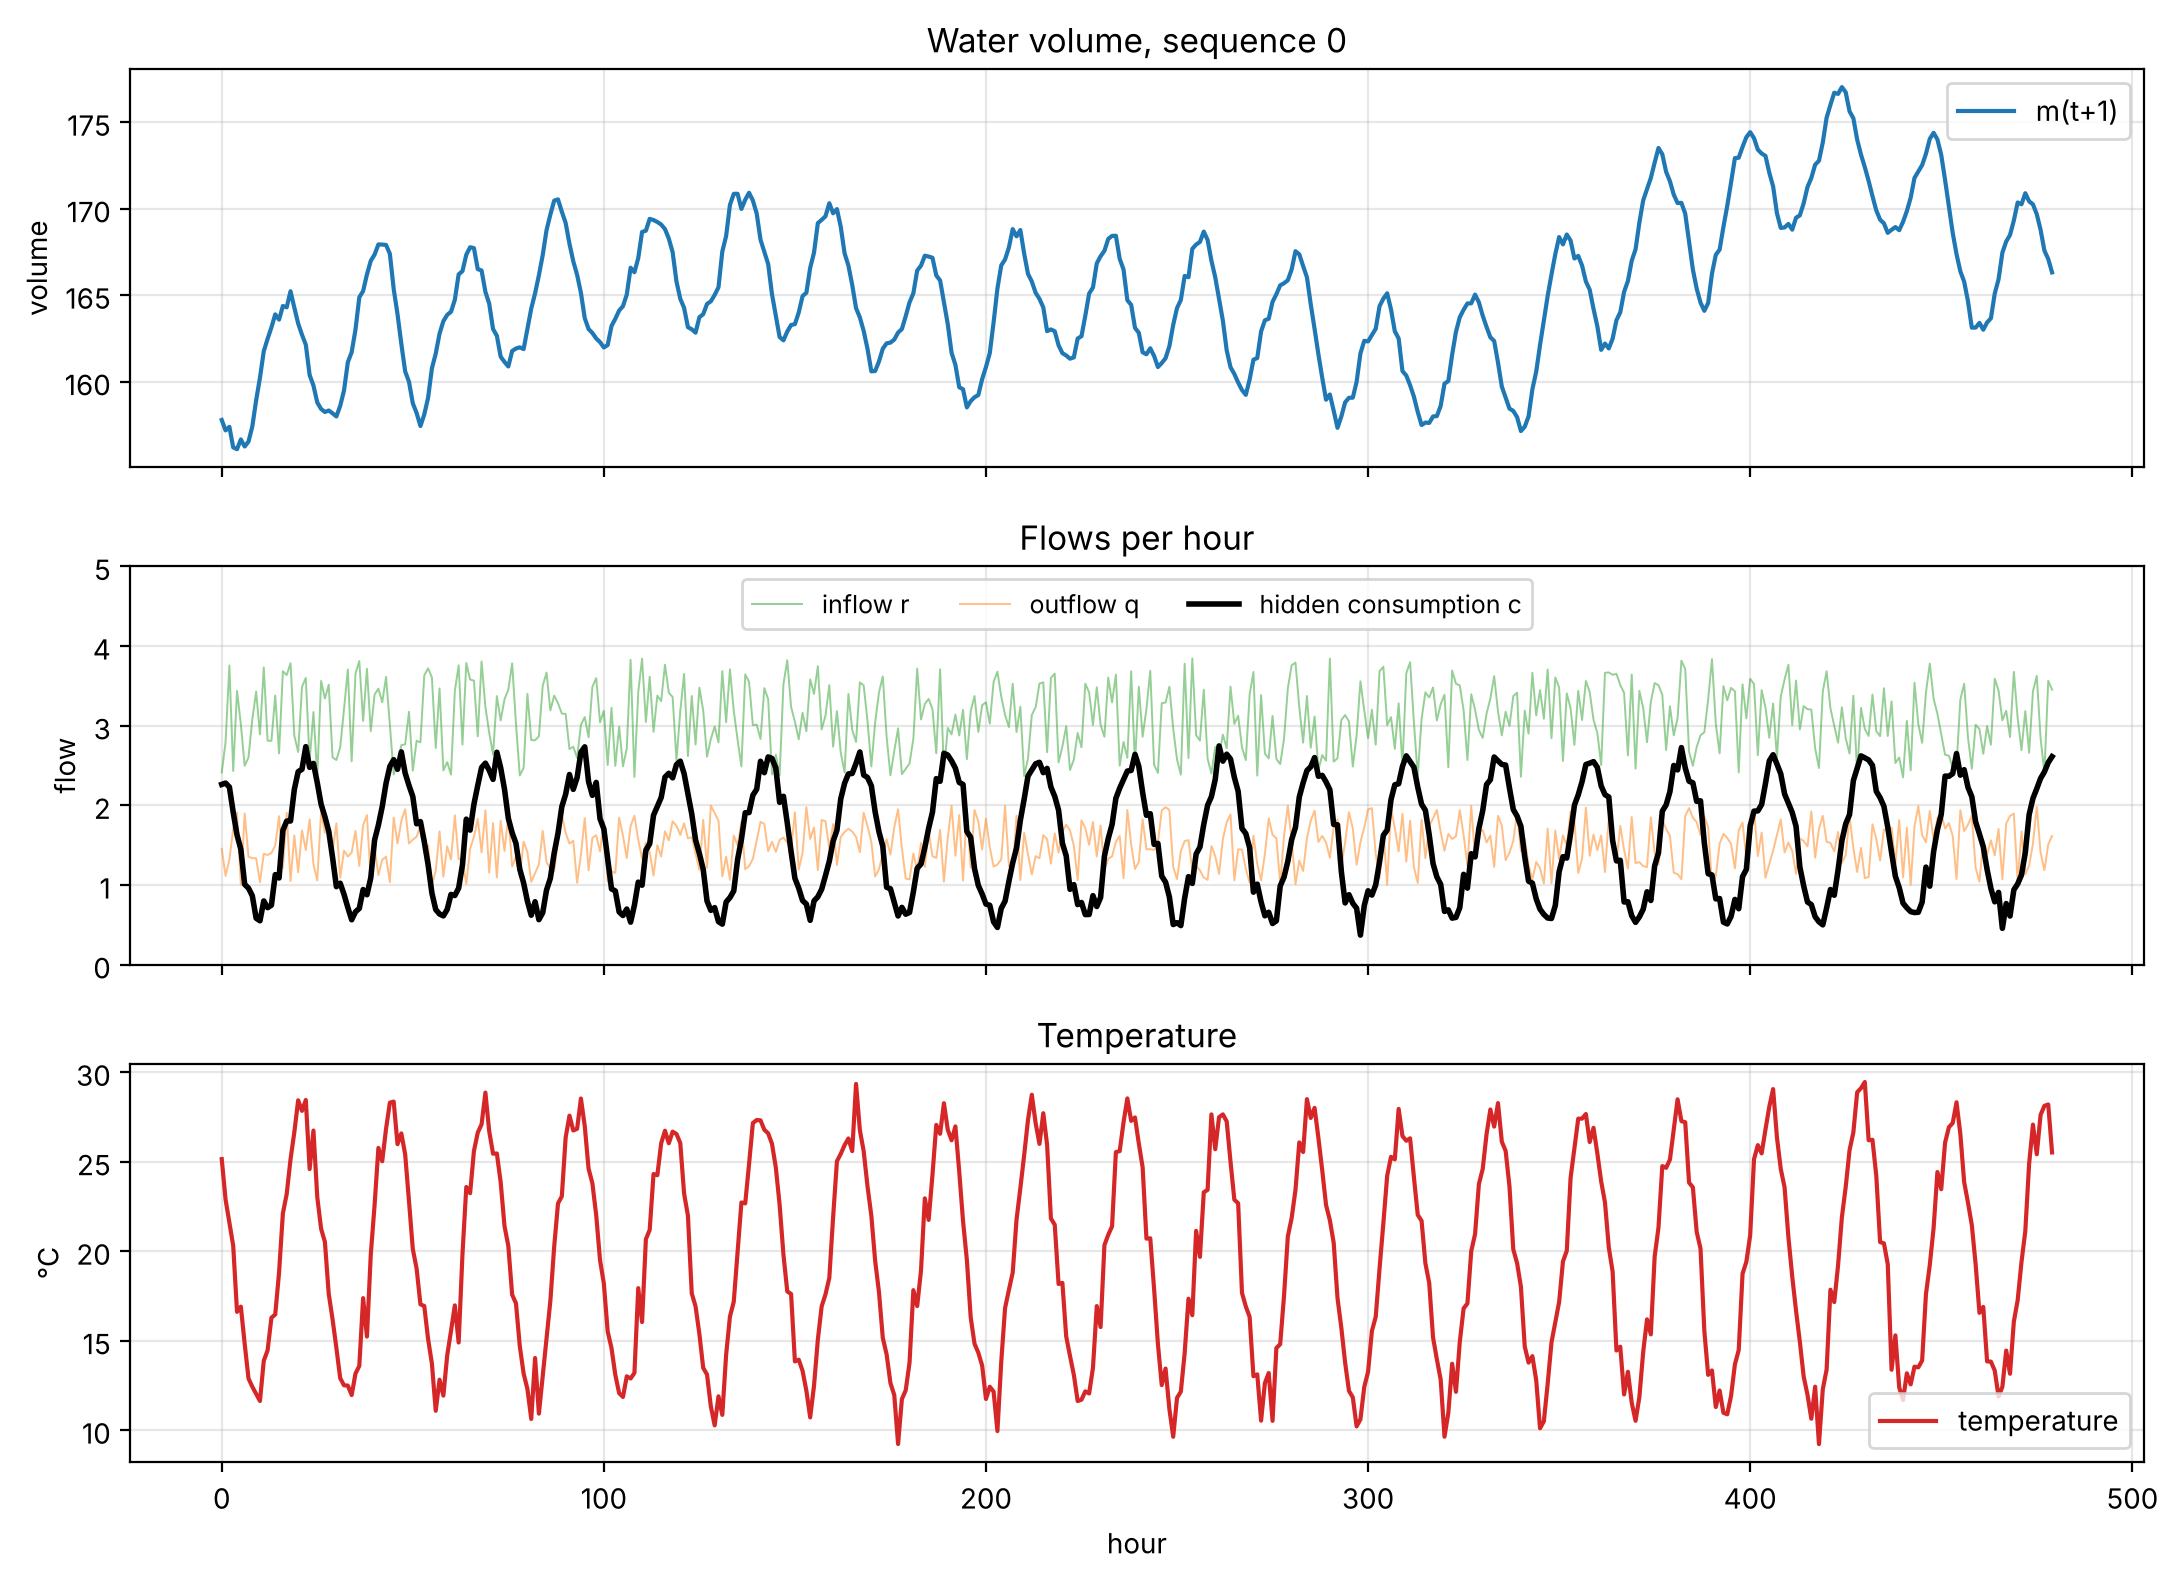

sequence 0: m in [156.09, 177.03]   c in [0.372, 2.747]   temp in [9.2, 29.5] °C


In [6]:
seq = 0
hours = np.arange(CONFIG["T"])
m_s, r_s, q_s, temp_s = (np.asarray(X[seq, :, i]) for i in range(4))
y_s, c_s = np.asarray(Y[seq]), np.asarray(C[seq])

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(hours, y_s, color="tab:blue", label="m(t+1)")
axes[0].set(title=f"Water volume, sequence {seq}", ylabel="volume")

axes[1].plot(hours, r_s, lw=0.7, alpha=0.5, color="tab:green", label="inflow r")
axes[1].plot(hours, q_s, lw=0.7, alpha=0.5, color="tab:orange", label="outflow q")
axes[1].plot(hours, c_s, lw=2.0, color="black", label="hidden consumption c")
axes[1].set(title="Flows per hour", ylabel="flow", ylim=(0, 5))

axes[2].plot(hours, temp_s, color="tab:red", label="temperature")
axes[2].set(title="Temperature", ylabel="°C", xlabel="hour")

for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend(loc="best")
axes[1].legend(loc="upper center", ncol=3, fontsize=9)
axes[2].legend(loc="best")
plt.tight_layout()
plt.show()

print(f"sequence {seq}: m in [{m_s.min():.2f}, {m_s.max():.2f}]   "
      f"c in [{c_s.min():.3f}, {c_s.max():.3f}]   temp in [{temp_s.min():.1f}, {temp_s.max():.1f}] °C")

assert len(axes) == 3
assert all(ax.get_title() and ax.get_ylabel() and ax.get_legend() is not None for ax in axes)


**Split and normalize.** Split train/test **by sequence**, not by timestep, so no timesteps from a test sequence leak into training through shared history. Normalize inputs (zero mean, unit variance) using statistics computed **only on the training split**. Keep the *unnormalized* `m(t)`, `r(t)`, `q(t)` around separately — you'll need the raw physical values later for the conservation-law reconstruction, which must not be done in normalized units.

### 4.3 Split, normalization and the cold-spell test set

`make_dataset` turns one call of the generator into a **bundle**, a dictionary with everything a training run needs.

- **Split by sequence:** sequences 0–299 train, 300–349 validation, 350–449 test. Whole sequences go to one split, so no test hour shares its history with a training hour. The **validation** set is used to choose things (the best epoch, `μ` in 8E.1). The test set is only measured.
- **Statistics from the training sequences actually used** (`x_mean`, `x_std` per feature; `y_mean`, `y_std` for the target), computed in float64. With `n_train=25` (low-data experiment, 8E.2) they come from those 25 sequences only, while validation and test stay the same.
- **Raw values kept:** `Xn_*` are the normalized network inputs, and `X_*` the raw ones. The balance needs raw `m, r, q` (`X[..., 0:3]`): `m + r − q` in normalized units has no physical meaning.
- **`DATA_SHIFT`** is the same data generated **15 °C colder** (same key, so the same random draws). It is normalized with **`DATA`'s statistics**, because a model trained on `DATA` must see cold inputs through the normalization it learned with. Only its test split is used, once, in section 8.

In [7]:
def make_dataset(key, n_train=300, temp_shift=0.0, stats_from=None, tag="main"):
    """Generate the data and split, normalize and package it as a bundle.

    key        : JAX PRNG key passed to generate_data
    n_train    : number of training sequences used (the first n_train of 0-299)
    temp_shift : temperature shift for generate_data
    stats_from : a bundle whose normalization statistics are reused (None = compute them)
    tag        : name of the bundle
    Returns a dict: X_*, Y_*, C_* raw arrays and Xn_* normalized inputs for * in tr/va/te,
    shapes (n, T, 6) and (n, T); x_mean, x_std (6,); y_mean, y_std floats; tag.
    """
    X, Y, C = generate_data(key, CONFIG["n_seq"], CONFIG["T"], temp_shift)
    n_tr_max, n_va = CONFIG["n_train"], CONFIG["n_val"]
    splits = {"tr": slice(0, n_train),
              "va": slice(n_tr_max, n_tr_max + n_va),
              "te": slice(n_tr_max + n_va, CONFIG["n_seq"])}
    d = {"tag": tag}
    for s, sl in splits.items():
        d[f"X_{s}"], d[f"Y_{s}"], d[f"C_{s}"] = X[sl], Y[sl], C[sl]

    if stats_from is None:
        # float64 so the statistics of ~144k steps are not affected by rounding
        x_tr, y_tr = np.asarray(d["X_tr"], np.float64), np.asarray(d["Y_tr"], np.float64)
        d["x_mean"], d["x_std"] = x_tr.mean(axis=(0, 1)), x_tr.std(axis=(0, 1))
        d["y_mean"], d["y_std"] = float(y_tr.mean()), float(y_tr.std())
    else:
        for k in ("x_mean", "x_std", "y_mean", "y_std"):
            d[k] = stats_from[k]

    for s in splits:
        xn = (np.asarray(d[f"X_{s}"], np.float64) - d["x_mean"]) / d["x_std"]
        d[f"Xn_{s}"] = jnp.asarray(xn, dtype=jnp.float32)
    return d


DATA = make_dataset(data_key)
DATA_SHIFT = make_dataset(data_key, temp_shift=CONFIG["temp_shift"], stats_from=DATA, tag="shift")
small = make_dataset(data_key, n_train=25, tag="n25")      # only for the check below


def seq_ids(Xs):
    """Identify each sequence by its first 5 volumes (a tuple per sequence)."""
    return {tuple(row) for row in np.asarray(Xs[:, :5, 0])}


xn_tr = np.asarray(DATA["Xn_tr"], np.float64)
dev_mean = np.abs(xn_tr.mean(axis=(0, 1))).max()
dev_std = np.abs(xn_tr.std(axis=(0, 1)) - 1).max()
full_mean = np.asarray(X, np.float64).mean(axis=(0, 1))
temp_diff = np.asarray(DATA["X_te"][..., 3] - DATA_SHIFT["X_te"][..., 3])
share_c0_main = float((DATA["C_te"] == 0).mean())
share_c0_cold = float((DATA_SHIFT["C_te"] == 0).mean())

print("Split (X):", DATA["X_tr"].shape, DATA["X_va"].shape, DATA["X_te"].shape)
print("x_mean:", np.round(DATA["x_mean"], 3))
print("x_std :", np.round(DATA["x_std"], 3))
print(f"y_mean = {DATA['y_mean']:.3f}   y_std = {DATA['y_std']:.3f}")
print(f"normalized training inputs: max |mean| = {dev_mean:.1e}   max |std - 1| = {dev_std:.1e}")
print(f"max |x_mean(train) - x_mean(all 450 sequences)| = {np.abs(DATA['x_mean'] - full_mean).max():.4f}")
print(f"n_train=25 bundle: y_mean = {small['y_mean']:.3f}, same validation and test arrays as DATA")
print(f"DATA_SHIFT: test temperature lower by {temp_diff.min():.4f} to {temp_diff.max():.4f} °C; "
      f"steps with c = 0: {100 * share_c0_cold:.1f} % of its test steps (DATA: {100 * share_c0_main:.1f} %)")

assert DATA["X_tr"].shape == (300, 480, 6) and DATA["X_va"].shape == (50, 480, 6) and DATA["X_te"].shape == (100, 480, 6)
ids = [seq_ids(DATA[f"X_{s}"]) for s in ("tr", "va", "te")]
assert [len(i) for i in ids] == [300, 50, 100]                        # no duplicates either
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2])     # disjoint splits
assert dev_mean < 1e-3 and dev_std < 1e-3
assert not np.allclose(DATA["x_mean"], full_mean)                      # training-only statistics
for k in ("X_va", "Y_va", "C_va", "X_te", "Y_te", "C_te"):
    assert bool(jnp.all(small[k] == DATA[k]))
assert small["X_tr"].shape[0] == 25 and not np.allclose(small["x_mean"], DATA["x_mean"])
assert np.array_equal(DATA_SHIFT["x_mean"], DATA["x_mean"]) and DATA_SHIFT["y_std"] == DATA["y_std"]
assert np.allclose(temp_diff, 15.0, atol=1e-4)                         # 15 °C colder, up to float32 rounding
assert bool(jnp.all(DATA_SHIFT["X_te"][..., 1:3] == DATA["X_te"][..., 1:3]))   # same r, q draws
del small


Split (X): (300, 480, 6) (50, 480, 6) (100, 480, 6)
x_mean: [156.477   3.098   1.499  19.886   0.479   0.495]
x_std : [16.676  0.433  0.288  5.824  0.288  0.284]
y_mean = 156.482   y_std = 16.721
normalized training inputs: max |mean| = 4.3e-09   max |std - 1| = 2.1e-09
max |x_mean(train) - x_mean(all 450 sequences)| = 0.3983
n_train=25 bundle: y_mean = 161.478, same validation and test arrays as DATA
DATA_SHIFT: test temperature lower by 15.0000 to 15.0000 °C; steps with c = 0: 14.4 % of its test steps (DATA: 0.0 %)


<a id='5'></a>
## 5. Task 5.2 — Conventional LSTM (the baseline, Option 1)

A standard LSTM that receives the observable variables and **predicts the mass directly**:

$$ \hat{m}(t+1) = \text{LSTM}_\theta\big(x(t)\big) $$

It has no knowledge of the conservation law — it has to learn everything from data. This is your baseline.

### The baseline in Flax

- **Many-to-many:** `nn.RNN` runs one `nn.LSTMCell` over the 480 steps and returns its hidden state `h(t)` at **every** step, shape (batch, T, 32). `Dense(1)` maps each `h(t)` to one number, so one forward pass predicts `m(t+1)` for all `t` at once. Each `h(t)` depends only on inputs up to `t`, never on later hours.
- **Initialization:** Flax uses an **orthogonal** initialization for the recurrent weights (`h → gates`) and zero biases. Orthogonal matrices keep the size of the hidden state roughly constant when it is multiplied step after step, which helps gradients travel through 480 steps.
- **Output scaling outside the module:** the target is around 156 with a spread of about 17, while a freshly initialized `Dense(1)` outputs values of order 1. So the network predicts a standardized value `o`, and `m̂ = y_mean + y_std · o` is applied outside the module (in `build_model`, section 6) with the training statistics. Without it, the baseline would spend most of its training learning an offset of 156, and the comparison would measure output scaling instead of physics.
- **Parameter count:** the LSTM has 4 gates. Each gate has an input kernel (6 × 32), a recurrent kernel (32 × 32) and a bias (32): 4 · (192 + 1,024 + 32) = **4,992**. `Dense(1)` adds 32 weights + 1 bias = 33, for **5,025** in total.

The check after the classes runs the untrained backbone and baseline on two training sequences.

In [8]:
class LSTMBackbone(nn.Module):
    """Recurrent LSTM layer returning the hidden state at every step.

    xs : (batch, T, features) normalized inputs -> (batch, T, hidden_size)
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs: (batch, T, features)
        return nn.RNN(nn.LSTMCell(features=self.hidden_size))(xs)


class ConventionalLSTM(nn.Module):
    """Predicts m(t+1) directly, as a standardized value.

    xs : (batch, T, 6) normalized inputs -> (batch, T) standardized output o;
    the physical prediction is y_mean + y_std * o (applied outside, see build_model).
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs (normalized): (batch, T, 6)
        h = LSTMBackbone(self.hidden_size)(xs)
        return nn.Dense(1)(h).squeeze(-1)


def n_parameters(params):
    """Total number of scalar parameters in a parameter pytree."""
    return sum(int(np.prod(p.shape)) for p in jax.tree_util.tree_leaves(params))


# Check on two training sequences, untrained
xs2 = DATA["Xn_tr"][:2]
k_bb, k_base = jax.random.split(run_key("check5_s112358"))
backbone = LSTMBackbone(CONFIG["hidden_size"])
h2 = backbone.apply(backbone.init(k_bb, xs2), xs2)
baseline = ConventionalLSTM(CONFIG["hidden_size"])
params_base = baseline.init(k_base, xs2)
o2 = baseline.apply(params_base, xs2)

print("hidden states h:", h2.shape, f"  values in [{float(h2.min()):.3f}, {float(h2.max()):.3f}]")
print("baseline output:", o2.shape)
print(f"parameters: backbone {n_parameters(params_base['params']['LSTMBackbone_0']):,}  "
      f"+ Dense(1) {n_parameters(params_base['params']['Dense_0'])}  = {n_parameters(params_base):,}")

assert h2.shape == (2, 480, 32) and o2.shape == (2, 480)
assert n_parameters(params_base) == 5025


hidden states h: (2, 480, 32)   values in [-0.983, 0.941]
baseline output: (2, 480)
parameters: backbone 4,992  + Dense(1) 33  = 5,025


<a id='6'></a>
## 6. Task 5.3 — Your model (the option your group chose in Phase A)

Implement **one** of the three non-baseline options from Phase A §2 — whichever your group chose and justified in Discussion 3. You only need the one matching your choice; the other two stubs below are there for reference (or if you want to compare more than one — optional, not required).

**Important, for all three options:** the model should receive `xs` **normalized** for the neural-network part, but must use the **original physical values** of `m`, `r`, `q` wherever the mass balance is used (reconstruction, or the physics loss term) — doing that arithmetic in normalized units would be physically meaningless.

### Option 2 — Soft constraint (not implemented)

The network has two free heads, `m̂(t+1)` and `ĉ(t)`, and the conservation law enters only through an extra loss term, `λ · (m̂ − m − r + q + ĉ)²`. Nothing in the architecture enforces the balance, and nothing forces `ĉ ≥ 0`. Phase A (Discussion 3) did not choose it for three reasons: it **guarantees no conservation**, since the penalty is traded against accuracy; it adds a hyperparameter `λ` that needs several training runs to tune; and the network must still learn the mass (around 156) directly, so with little data it should behave more like the baseline.

### Option 3 — Hard constraint (not implemented)

The network predicts only `ĉ(t) = softplus(·) ≥ 0`, and the mass comes from the balance, `m̂(t+1) = m + r − q − ĉ`, in raw units. Conservation holds **exactly**, before training and on any input. Phase A (Discussion 3) notes that it would be sufficient for this simulation, where the balance is exact. It was not chosen because a real balance is rarely complete (sensor error, unmetered seepage or runoff): a hard constraint then forces every mismatch into `ĉ`, and `ĉ ≥ 0` **cannot represent a net unmetered gain**. Option 4 below keeps Option 3's structure and adds an explicit correction `δ` for that case.

### Option 4 — Residual correction

Like Option 3, but the network also predicts a small correction `δ(t)` to absorb unmodelled effects:

$$ \hat{m}(t+1) = m(t) + r(t) - q(t) - \hat{c}(t) + \delta(t) $$

Useful if you think the conservation law alone doesn't fully capture the true dynamics — but conservation is no longer exact, so watch how large `δ(t)` grows in §8's physical-error metric.

### Our model: Option 4 in Flax

- **Two heads on the same LSTM:** `head_c` → `softplus` gives `ĉ(t) > 0` (smooth everywhere, so gradients never stall at zero, unlike `relu`); `head_delta` gives `δ(t)` with no constraint.
- **The balance closes the prediction:** `m̂(t+1) = ((m + r) − q) − ĉ + δ`, with the **raw** `m, r, q` passed separately from the normalized network input. The network only has to learn a term of size about 1–2; the large part (around 156) is given by the measurements. The order of the operations is fixed and is the same in the metrics of section 8, so the balance is evaluated identically in the model and in the checks.
- **No output scaling:** `ĉ` and `δ` are already in physical units of the right size, so unlike the baseline nothing is rescaled.
- **What the loss can see:** only `ĉ − δ` enters `m̂`. Under a plain MSE a larger `ĉ` and a more negative `δ` give the same prediction, so `ĉ` alone need not be the true consumption (this is tested in section 8 and in 8E.1).
- **Parameters:** the same backbone (4,992) plus two heads of 33: **5,058**.

The check runs the untrained model on two training sequences: it must already satisfy the balance, because the balance is part of the architecture, not something it learns.

In [9]:
class ResidualCorrectionLSTM(nn.Module):
    """Option 4: hard constraint plus a small learned correction delta(t).

    xs_norm                : (batch, T, 6) normalized network input
    m_phys, r_phys, q_phys : (batch, T) RAW physical values
    Returns (m_pred, c_hat, delta), each (batch, T), in physical units.
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm, m_phys, r_phys, q_phys):
        h = LSTMBackbone(self.hidden_size)(xs_norm)                        # (batch, T, hidden)
        c_hat = nn.softplus(nn.Dense(1, name="head_c")(h).squeeze(-1))     # > 0
        delta = nn.Dense(1, name="head_delta")(h).squeeze(-1)              # unconstrained
        # Balance in raw units, fixed order of operations (the metrics use the same one)
        m_pred = ((m_phys + r_phys) - q_phys) - c_hat + delta
        return m_pred, c_hat, delta


# Untrained check on two training sequences
xr2 = DATA["X_tr"][:2]
opt4 = ResidualCorrectionLSTM(CONFIG["hidden_size"])
params_opt4 = opt4.init(run_key("check6_s112358"), xs2, xr2[..., 0], xr2[..., 1], xr2[..., 2])
m_pred2, c_hat2, delta2 = opt4.apply(params_opt4, xs2, xr2[..., 0], xr2[..., 1], xr2[..., 2])
balance2 = float(jnp.max(jnp.abs(m_pred2 - (xr2[..., 0] + xr2[..., 1] - xr2[..., 2] - c_hat2 + delta2))))

print("m_pred, c_hat, delta:", m_pred2.shape, c_hat2.shape, delta2.shape)
print(f"untrained: c_hat in [{float(c_hat2.min()):.3f}, {float(c_hat2.max()):.3f}]   "
      f"delta in [{float(delta2.min()):.3f}, {float(delta2.max()):.3f}]")
print(f"max |m_pred - (m + r - q - c_hat + delta)| = {balance2:.1e}")
print(f"parameters: {n_parameters(params_opt4):,}")

assert m_pred2.shape == c_hat2.shape == delta2.shape == (2, 480)
assert n_parameters(params_opt4) == 5058
assert bool(jnp.all(c_hat2 > 0))
assert balance2 < 1e-3


m_pred, c_hat, delta: (2, 480) (2, 480) (2, 480)
untrained: c_hat in [0.427, 1.103]   delta in [-0.550, 0.477]
max |m_pred - (m + r - q - c_hat + delta)| = 0.0e+00
parameters: 5,058


### A uniform interface for the two models

`build_model(kind, data)` hides the differences between the two models, so the training and evaluation code of sections 7–8 is written once. `init_fn(key)` creates the parameters, and `predict_fn(params, xn, x_raw)` always returns `(m_pred, c_hat, delta)` in **physical units**: for the baseline it applies `y_mean + y_std · output` with **this bundle's** training statistics and returns `None` for `c_hat` and `delta`. For Option 4 it passes the raw `m, r, q` to the balance.

In [10]:
def build_model(kind, data):
    """Build one model with a common interface.

    kind : "baseline" (Option 1) or "option4" (residual correction)
    data : bundle from make_dataset (gives the output scaling and a dummy input)
    Returns (model, init_fn, predict_fn):
      init_fn(key)                   -> params
      predict_fn(params, xn, x_raw)  -> (m_pred, c_hat, delta), each (B, T) in physical
                                        units; c_hat = delta = None for the baseline
      with xn (B, T, 6) normalized and x_raw (B, T, 6) raw inputs.
    """
    xn0, x0 = data["Xn_tr"][:1], data["X_tr"][:1]
    if kind == "baseline":
        model = ConventionalLSTM(CONFIG["hidden_size"])
        y_mean, y_std = data["y_mean"], data["y_std"]

        def init_fn(key):
            return model.init(key, xn0)

        def predict_fn(params, xn, x_raw):
            return y_mean + y_std * model.apply(params, xn), None, None
    elif kind == "option4":
        model = ResidualCorrectionLSTM(CONFIG["hidden_size"])

        def init_fn(key):
            return model.init(key, xn0, x0[..., 0], x0[..., 1], x0[..., 2])

        def predict_fn(params, xn, x_raw):
            return model.apply(params, xn, x_raw[..., 0], x_raw[..., 1], x_raw[..., 2])
    else:
        raise ValueError(f"unknown model kind: {kind}")
    return model, init_fn, predict_fn


for kind in ("baseline", "option4"):
    _, init_fn, predict_fn = build_model(kind, DATA)
    params = init_fn(run_key(f"check6_{kind}_s112358"))
    m_pred, c_hat, delta = predict_fn(params, DATA["Xn_tr"][:2], DATA["X_tr"][:2])
    mean_pred = float(m_pred.mean())
    print(f"{kind:8s}: m_pred {m_pred.shape}, mean {mean_pred:.2f} "
          f"(y_mean {DATA['y_mean']:.2f} ± 2·y_std = ±{2 * DATA['y_std']:.2f}), "
          f"c_hat is None: {c_hat is None}, {n_parameters(params):,} parameters")
    assert m_pred.shape == (2, 480)
    assert abs(mean_pred - DATA["y_mean"]) < 2 * DATA["y_std"]
    assert (c_hat is None) == (kind == "baseline")


baseline: m_pred (2, 480), mean 154.48 (y_mean 156.48 ± 2·y_std = ±33.44), c_hat is None: True, 5,025 parameters


option4 : m_pred (2, 480), mean 176.76 (y_mean 156.48 ± 2·y_std = ±33.44), c_hat is None: False, 5,058 parameters


<a id='7'></a>
## 7. Task 5.4 — Train the baseline model and your model under identical conditions

- **Baseline (§5, Option 1):** MSE on `m(t+1)` directly.
- **Your model (§6):** the loss depends on which option you implemented —
  - **Option 2 (soft constraint):** `L = L_pred + λ·L_physics` (§6). `λ` is an extra hyperparameter — try a few values (e.g. `0.1, 1.0, 10.0`) and see how it trades off prediction accuracy against conservation.
  - **Option 3 (hard constraint) / Option 4 (residual correction):** MSE on the *reconstructed* `m̂(t+1)`, not on `ĉ(t)` directly — the true `c(t)` must not be used for supervision.
- Same optimizer, learning rate, hidden size, and number of epochs for both models — otherwise you're no longer measuring the effect of the architecture alone. Reasonable starting values: `hidden_size=32`, `Adam(learning_rate=1e-2)`, `~300` epochs, `batch_size=32` sequences.
- **Use mini-batch training**: at each step, sample (or shuffle-and-slice) a batch of `batch_size` sequences from the training set rather than using all sequences at once. Reshuffle sequence order at the start of every epoch, using `jax.random.permutation` (splitting your key each time) so the shuffling stays reproducible.
- Wrap the training step in `jax.jit` and record training time for both models.
- Plot training loss curves for both on the same axes (log scale is usually clearer).

### How training works here

- **Mini-batches of sequences.** A batch is 32 whole sequences of 480 steps (inputs `xn`, raw values `x`, target `y`). The LSTM runs through each one from the first hour, so every prediction sees its full history. 300 training sequences give 9 batches of 32 and one of 12. The epoch's training loss is the mean over batches weighted by their size, so it equals the MSE over all training steps.
- **Reshuffling with split keys.** At every epoch the key is split and `jax.random.permutation` draws a new order of the sequences. Each split gives a fresh key, so no random draw is repeated and the whole run is reproducible from its `run_key`.
- **The loss.** MSE on `m(t+1)` in **physical units** for both models; the optional `μ · mean(δ²)` term is used only in experiment 8E.1. `value_and_grad` differentiates the loss with respect to the parameters, and the step is compiled once per run with `jax.jit` (JAX compiles it once for each batch shape: 32 and 12).
- **Gradient clipping.** Before Adam (learning rate 1e-2), the gradient is rescaled whenever its global norm exceeds 1.0. Through 480 recurrent steps an occasional gradient can be very large; clipping keeps one bad batch from undoing training. It is applied identically to both models.
- **Best epoch on validation.** After every epoch the validation MSE is computed, and training returns the parameters of the epoch where it was lowest. All 300 epochs always run, so training times stay comparable. Only the validation set is used for this choice, never the test set.
- **`C` is in no batch.** A batch holds exactly `xn`, `x` and `y`. The true consumption would hand the answer to the models (`c = m + r − q − m(t+1)`), and in a real reservoir it is not measured at all.

In [11]:
def make_train_step(loss_fn, optimizer):
    @jax.jit
    def step(params, opt_state, batch):
        loss, grads = jax.value_and_grad(loss_fn)(params, batch)
        updates, opt_state = optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state, loss
    return step

HIDDEN_SIZE = CONFIG["hidden_size"]
EPOCHS = CONFIG["epochs"]
BATCH_SIZE = CONFIG["batch_size"]
# Clip the global gradient norm, then Adam: identical for every run
optimizer = optax.chain(optax.clip_by_global_norm(CONFIG["clip_norm"]),
                        optax.adam(CONFIG["learning_rate"]))


def make_batch(X_xs, extra_arrays, y, idx):
    """One mini-batch of whole sequences.

    X_xs : (N, T, 6) normalized inputs; extra_arrays : dict of (N, ...) arrays
    (here {"x": raw inputs (N, T, 6)}); y : (N, T) targets; idx : (B,) sequence indices.
    Returns {"xn": (B, T, 6), "y": (B, T), plus each extra array indexed by idx}.
    """
    return {"xn": X_xs[idx], "y": y[idx], **{k: v[idx] for k, v in extra_arrays.items()}}


def make_loss_fn(predict_fn, mu=0.0):
    """Training loss: MSE on m(t+1) in physical units (+ mu * mean(delta^2) if mu > 0).

    predict_fn : from build_model. Returns loss(params, batch) -> scalar.
    """
    def loss(params, batch):
        m_pred, _, delta = predict_fn(params, batch["xn"], batch["x"])
        mse = jnp.mean((m_pred - batch["y"]) ** 2)
        if mu > 0 and delta is not None:      # Python-level choice, fixed when the function is built
            return mse + mu * jnp.mean(delta ** 2)
        return mse
    return loss


def make_val_fn(predict_fn, data):
    """Jitted validation MSE on data's validation split (no penalty term).

    Returns val(params) -> scalar MSE over the (50, 480) validation targets.
    """
    @jax.jit
    def val(params):
        m_pred, _, _ = predict_fn(params, data["Xn_va"], data["X_va"])
        return jnp.mean((m_pred - data["Y_va"]) ** 2)
    return val


def train_model(model, params, loss_fn, key, X_xs, extra_arrays, y,
                epochs=EPOCHS, batch_size=BATCH_SIZE, val_fn=None):
    """Mini-batch training with reshuffling and best-epoch selection on validation.

    model        : unused (kept for the template's signature); params : initial parameters
    loss_fn      : loss(params, batch); key : PRNG key of this run (split every epoch)
    X_xs         : (N, T, 6) normalized inputs; extra_arrays : {"x": (N, T, 6) raw inputs}
    y            : (N, T) targets; val_fn : val(params) -> validation MSE
    Returns (best_params, history) with history = {"train": [epochs floats],
    "val": [epochs floats], "best_epoch": 1-based epoch of the lowest validation MSE}.
    """
    step = make_train_step(loss_fn, optimizer)      # jitted once for the whole run
    opt_state = optimizer.init(params)
    n = X_xs.shape[0]
    history = {"train": [], "val": [], "best_epoch": epochs}
    best_params, best_val = params, float("inf")

    for epoch in range(epochs):
        key, k_perm = jax.random.split(key)
        order = jax.random.permutation(k_perm, n)
        total = 0.0
        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]
            params, opt_state, loss = step(params, opt_state, make_batch(X_xs, extra_arrays, y, idx))
            total += float(loss) * len(idx)          # weight by batch size (last batch is smaller)
        history["train"].append(total / n)

        if val_fn is not None:
            val = float(val_fn(params))
            history["val"].append(val)
            if val < best_val:
                best_val, best_params, history["best_epoch"] = val, params, epoch + 1
        else:
            best_params = params
    return best_params, history


### Runs and cache

`run_experiment` trains one model from its own key (`run_key(name)`, split into an initialization key and a training key), times the whole training including compilation, and keeps what sections 8–11 need: loss histories, best epoch, time, parameter count and test predictions (plus `ĉ`, `δ` for Option 4, and the predictions on extra bundles such as the cold spell when asked). Trained parameters are not kept. `run_cached` stores each result as `results/<name>.npz` and reloads it on the next run, and records every run in `RUNS` for the final checks.

In [12]:
def run_experiment(name, kind, data, mu=0.0, eval_sets=None, seed=CONFIG["seed"]):
    """Train one model and collect its results.

    name : run name (gives the key); kind : "baseline" or "option4"; data : bundle
    mu   : weight of the delta penalty (8E.1); eval_sets : {prefix: bundle} to also predict on
    Returns a dict: train_loss, val_loss (epochs,), best_epoch, time (s), n_params,
    test_m_pred (n_test, T) [+ test_c_hat, test_delta], and the same per eval_sets prefix.
    """
    k_init, k_train = jax.random.split(run_key(name, seed))
    _, init_fn, predict_fn = build_model(kind, data)
    params = init_fn(k_init)

    t0 = time.time()
    params, hist = train_model(None, params, make_loss_fn(predict_fn, mu), k_train,
                               data["Xn_tr"], {"x": data["X_tr"]}, data["Y_tr"],
                               val_fn=make_val_fn(predict_fn, data))
    elapsed = time.time() - t0

    res = {"train_loss": np.array(hist["train"]), "val_loss": np.array(hist["val"]),
           "best_epoch": hist["best_epoch"], "time": elapsed, "n_params": n_parameters(params)}
    for prefix, d in [("test", data)] + list((eval_sets or {}).items()):
        m_pred, c_hat, delta = predict_fn(params, d["Xn_te"], d["X_te"])
        res[f"{prefix}_m_pred"] = np.asarray(m_pred)
        if c_hat is not None:
            res[f"{prefix}_c_hat"], res[f"{prefix}_delta"] = np.asarray(c_hat), np.asarray(delta)
    return res


RUNS = {}   # name -> settings of every run used in this notebook (checked in section 11)


def run_cached(name, kind, data, mu=0.0, eval_sets=None, seed=CONFIG["seed"]):
    """run_experiment with a cache in results/<name>.npz; records the run in RUNS.

    Same arguments and return value as run_experiment. Prints one line per run.
    """
    path = os.path.join("results", f"{name}.npz")
    if CONFIG["use_cache"] and os.path.exists(path):
        with np.load(path) as f:
            res = {k: (f[k].item() if f[k].ndim == 0 else f[k]) for k in f.files}
        status = "loaded from cache"
    else:
        res = run_experiment(name, kind, data, mu, eval_sets, seed)
        np.savez(path, **res)
        status = "computed"
    RUNS[name] = {"kind": kind, "tag": data["tag"], "mu": mu, "seed": seed}
    print(f"{name}: {status}")
    return res


### Main runs

The baseline and Option 4 are trained on `DATA` with exactly the same settings (`CONFIG`), each from its own key. Both also predict on the cold-spell test set, used once in section 8. The first execution trains both models; afterwards the results load from `results/`.

In [13]:
RESULTS = {}
RESULTS["baseline"] = run_cached("baseline_s112358", "baseline", DATA, eval_sets={"shift": DATA_SHIFT})
RESULTS["opt4"] = run_cached("opt4_s112358", "option4", DATA, eval_sets={"shift": DATA_SHIFT})


baseline_s112358: loaded from cache
opt4_s112358: loaded from cache


### Loss curves

Training (solid) and validation (dashed) MSE per epoch for both models, on log–log axes so that the first epochs and the last ones are both readable. The dot marks the epoch whose parameters are kept (lowest validation MSE). Both losses are MSE of `m(t+1)` in physical units, so the two models are on the same scale.

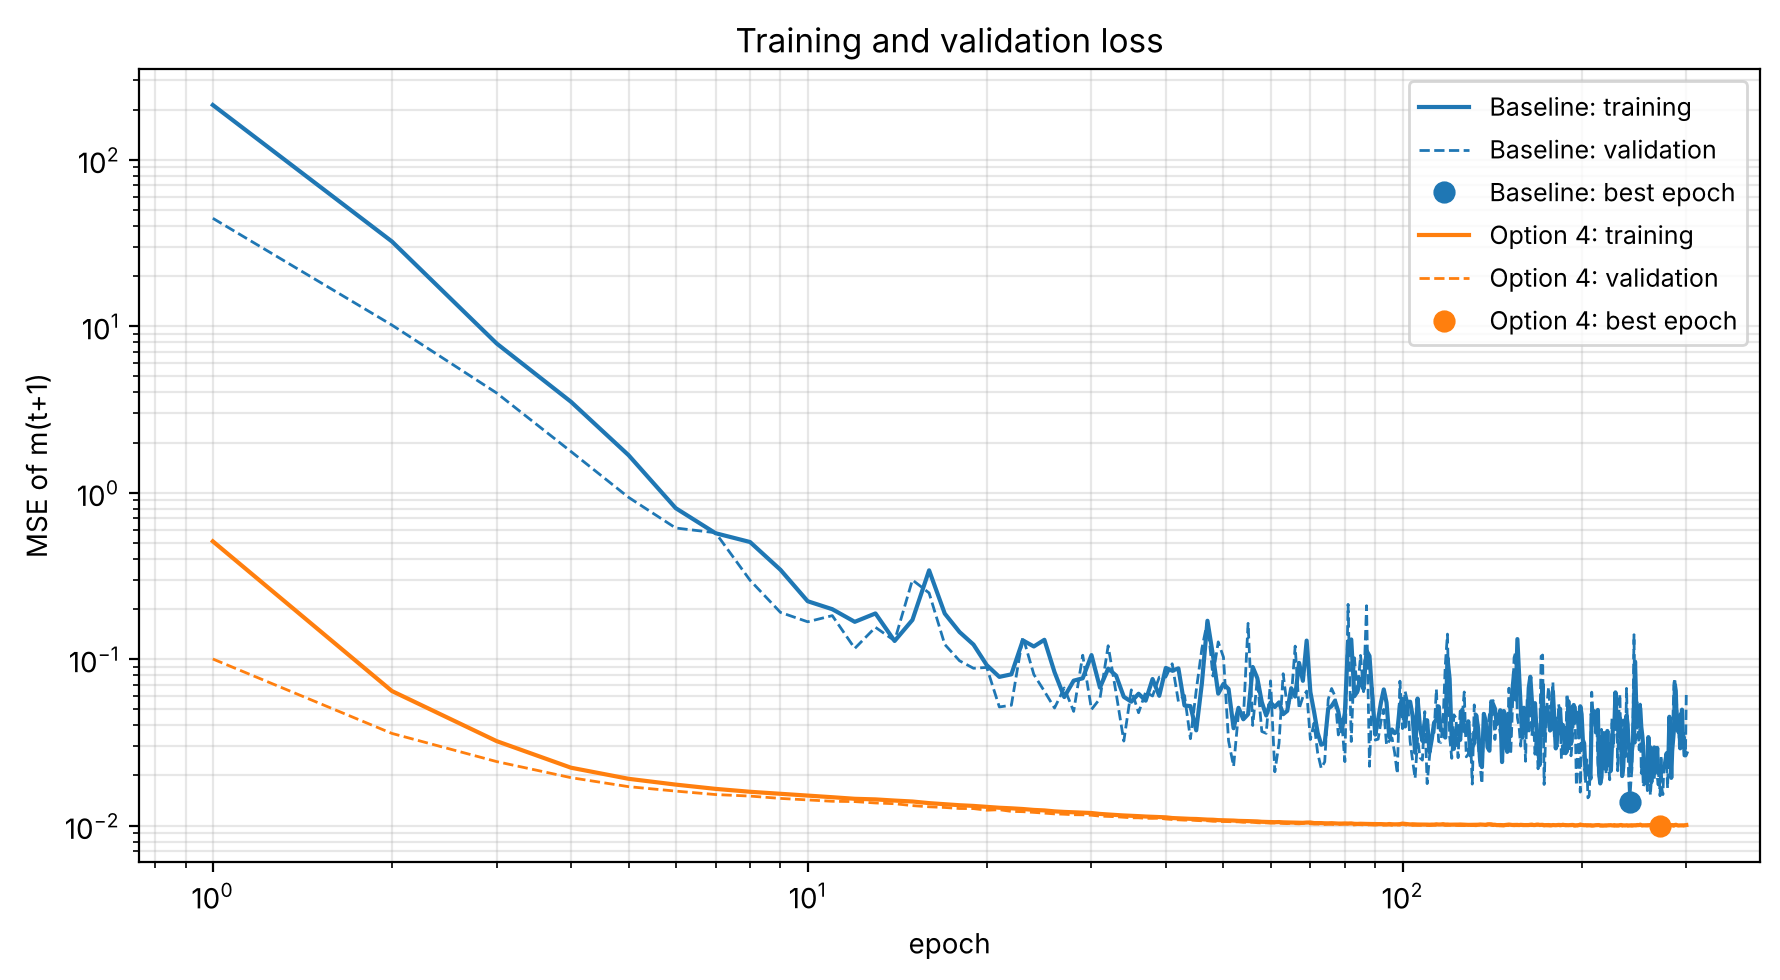

Baseline  training loss 213 -> 0.02722   best epoch 241   validation MSE there 0.01395
Option 4  training loss 0.5097 -> 0.01007   best epoch 271   validation MSE there 0.00992


In [14]:
def plot_losses(runs):
    """Plot training and validation loss of several runs and print one line per run.

    runs : {label: result dict from run_cached} (uses train_loss, val_loss, best_epoch)
    """
    fig, ax = plt.subplots(figsize=(9, 5))
    for (label, res), color in zip(runs.items(), ["tab:blue", "tab:orange"]):
        epochs = np.arange(1, len(res["train_loss"]) + 1)
        best = res["best_epoch"]
        ax.plot(epochs, res["train_loss"], color=color, lw=1.5, label=f"{label}: training")
        ax.plot(epochs, res["val_loss"], color=color, lw=1.0, ls="--", label=f"{label}: validation")
        ax.plot(best, res["val_loss"][best - 1], "o", color=color, ms=7,
                label=f"{label}: best epoch")
    ax.set(xscale="log", yscale="log", xlabel="epoch", ylabel="MSE of m(t+1)",
           title="Training and validation loss")
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    for label, res in runs.items():
        best = res["best_epoch"]
        print(f"{label:9s} training loss {res['train_loss'][0]:.4g} -> {res['train_loss'][-1]:.4g}   "
              f"best epoch {best}   validation MSE there {res['val_loss'][best - 1]:.5f}")


plot_losses({"Baseline": RESULTS["baseline"], "Option 4": RESULTS["opt4"]})


### Conclusion of section 7

- **Baseline.** Its training loss falls from 213 to 0.02722. The first epochs are spent learning the level of the mass (around 156), which it must produce itself. After about epoch 20 the curves no longer fall smoothly: the validation MSE jumps from one epoch to the next, sometimes by close to an order of magnitude. Best-epoch selection keeps **epoch 241**, validation MSE **0.01395**, one of the dips of that noisy curve. Because it is the lowest of many noisy values, it is somewhat optimistic; section 8 measures the model on the independent test set.
- **Option 4.** Its very first epoch averages 0.5097, already lower than the baseline's first seven epochs, because the balance supplies the mass and the network only learns `ĉ − δ`. Both curves fall smoothly and flatten out; the best epoch is **271**, with validation MSE **0.00992**, so the selection changes little here.
- **Noise floor.** The consumption has a random part with standard deviation 0.1 that no input can predict, so no model can go much below an MSE of 0.1² = 0.01. Option 4 has essentially reached that level; the baseline's best validation MSE is about 40 % higher than Option 4's.
- In the first epochs the validation loss lies below the training loss. This is not a sign of leakage: the training value is the average over an epoch during which the weights are still improving, while the validation value is measured with the weights at the end of the epoch.

<a id='8'></a>
## 8. Metrics and comparison

Compute all four metrics on the **held-out test set** for both models:

| Metric | Formula |
|---|---|
| **MSE** | `mean((m̂(t+1) - m(t+1))^2)` |
| **MAE** | `mean(\|m̂(t+1) - m(t+1)\|)` |
| **Physical error** | `mean(max(0, -(m(t) + r(t) - q(t) - m̂(t+1))))` — magnitude of implied negative consumption |
| **Training time** | wall-clock time for the training loop |

**Expected pattern (depends on which option you implemented in §6):**
- The **baseline** (Option 1) should show a non-zero physical error — nothing stops it from implying negative consumption.
- **Option 2 (soft constraint):** physical error should be *reduced* relative to the baseline but generally still nonzero — how much depends on `λ`; larger `λ` should push it closer to zero, at some cost to MSE.
- **Option 3 (hard constraint):** physical error should be **exactly zero**, always — not just small. `softplus` guarantees `ĉ(t) ≥ 0`, so the implied consumption `m(t)+r(t)-q(t)-m̂(t+1) = ĉ(t)` can never be negative, regardless of training quality.
- **Option 4 (residual correction):** unlike Option 3, `δ(t)` has no positivity constraint, so physical error is generally nonzero — if `δ(t)` grows large, it can exceed Option 3's.

If your results don't roughly match the pattern for your chosen option, check: are both models trained under identical conditions? Does your model's mass computation (or physics loss term) use raw, unnormalized `m, r, q`? Is `c(t)` leaking into either model's inputs anywhere?

### Two axes: accuracy and physical consistency

- **Accuracy:** MSE and MAE of `m̂(t+1)` against the true `m(t+1)` on the 100 test sequences (48,000 steps). The MSE weights large errors more; the MAE is in volume units.
- **Implied consumption:** any prediction implies a consumption `c_implied = ((m + r) − q) − m̂(t+1)`, the water that must have left unmetered for the prediction to be right. For Option 4 it equals `ĉ − δ` (up to float32 rounding), not `ĉ`.
- **Physical error is one-sided:** only a **negative** implied consumption is impossible (water appearing from nothing); a positive one of the wrong size is just an inaccurate prediction, already counted by the MSE. So the physical error averages `max(0, −c_implied)` over all steps, and the **violation share** is the percentage of steps where `c_implied < 0`.
- **What a zero means:** neither model guarantees `c_implied ≥ 0`. The baseline has no structure for it, and Option 4's `δ` is unconstrained, so a step with `δ > ĉ` violates the balance. A zero below is therefore a result **measured on this test set**, not a guarantee (only Option 3 would give one).

The balance is computed with the raw `m, r, q` in float32 and in the same order of operations as Option 4, so the model and the metric evaluate it identically. The table also reports the training time of section 7 (wall clock, including JIT compilation).

In [15]:
def compute_metrics(m_pred, m, r, q, y):
    """Return (mse, mae, physical_error) — see formulas above.

    m_pred, m, r, q, y : (N, T) arrays in physical units (m, r, q raw; y = true m(t+1)).
    physical_error = mean(max(0, -c_implied)), c_implied = ((m + r) - q) - m_pred.
    """
    m_pred, m, r, q, y = (np.asarray(a, np.float32) for a in (m_pred, m, r, q, y))
    c_implied = ((m + r) - q) - m_pred                  # same order as Option 4, float32
    err = (m_pred - y).astype(np.float64)
    mse, mae = float(np.mean(err ** 2)), float(np.mean(np.abs(err)))
    phys = float(np.mean(np.maximum(0.0, -c_implied.astype(np.float64))))
    return mse, mae, phys


def violation_share(m_pred, m, r, q):
    """Fraction of steps whose implied consumption ((m + r) - q) - m_pred is negative."""
    m_pred, m, r, q = (np.asarray(a, np.float32) for a in (m_pred, m, r, q))
    return float(np.mean((((m + r) - q) - m_pred) < 0))


def evaluate(result, data, prefix="test"):
    """Metrics of one run's stored predictions on data's test split.

    result : dict from run_cached; data : the bundle the predictions were made on
    prefix : which stored predictions to use ("test", or "shift" with DATA_SHIFT)
    Returns {mse, mae, phys, share}, plus for Option 4 runs the diagnostics
    {mean_delta, mean_abs_delta, max_abs_delta, mae_c, mae_eff} (uses the true C).
    """
    X, y = data["X_te"], data["Y_te"]
    m, r, q = X[..., 0], X[..., 1], X[..., 2]
    m_pred = result[f"{prefix}_m_pred"]
    mse, mae, phys = compute_metrics(m_pred, m, r, q, y)
    out = {"mse": mse, "mae": mae, "phys": phys, "share": violation_share(m_pred, m, r, q)}
    if f"{prefix}_c_hat" in result:
        c_hat, delta = result[f"{prefix}_c_hat"], result[f"{prefix}_delta"]
        c_true = np.asarray(data["C_te"], np.float64)
        out.update(mean_delta=float(np.mean(delta)), mean_abs_delta=float(np.mean(np.abs(delta))),
                   max_abs_delta=float(np.max(np.abs(delta))),
                   mae_c=float(np.mean(np.abs(c_hat - c_true))),
                   mae_eff=float(np.mean(np.abs((c_hat - delta) - c_true))))
    return out


EVAL = {name: evaluate(RESULTS[name], DATA) for name in ("baseline", "opt4")}
rows = [("MSE", "mse", "{:.5f}"), ("MAE", "mae", "{:.4f}"), ("Physical error", "phys", "{:.3g}"),
        ("Steps with negative implied c (%)", "share", None), ("Training time (s)", "time", "{:.0f}")]
print(f"{'Metric (test set)':36s}{'Baseline':>12s}{'Option 4':>12s}")
for label, key, fmt in rows:
    cells = []
    for name in ("baseline", "opt4"):
        v = RESULTS[name]["time"] if key == "time" else EVAL[name][key]
        cells.append(f"{100 * v:.3f}" if key == "share" else fmt.format(v))
    print(f"{label:36s}{cells[0]:>12s}{cells[1]:>12s}")

ratio = EVAL["baseline"]["mse"] / EVAL["opt4"]["mse"]
print(f"\nReading:")
print(f"- Accuracy: the baseline's test MSE is {ratio:.2f} times Option 4's "
      f"({'Option 4 is more accurate' if ratio > 1 else 'the baseline is more accurate'}).")
why = {"baseline": "nothing in the baseline's architecture prevents a negative implied consumption",
       "opt4": "delta is unconstrained, so any step with delta > c_hat would break the balance"}
for name, label in (("baseline", "Baseline"), ("opt4", "Option 4")):
    e = EVAL[name]
    if e["phys"] == 0:
        print(f"- {label}: physical error 0 measured on this test set. Not a guarantee: {why[name]}.")
    else:
        print(f"- {label}: physical error {e['phys']:.3g} > 0: on {100 * e['share']:.3f} % of test steps the "
              f"prediction implies water appearing from nothing ({why[name]}).")

assert all(np.isfinite(v) for e in EVAL.values() for v in e.values())
assert all(np.isfinite(RESULTS[n]["time"]) for n in ("baseline", "opt4"))


Metric (test set)                       Baseline    Option 4
MSE                                      0.01529     0.01015
MAE                                       0.0956      0.0804
Physical error                          2.24e-05           0
Steps with negative implied c (%)          0.013       0.000
Training time (s)                            137         129

Reading:
- Accuracy: the baseline's test MSE is 1.51 times Option 4's (Option 4 is more accurate).
- Baseline: physical error 2.24e-05 > 0: on 0.013 % of test steps the prediction implies water appearing from nothing (nothing in the baseline's architecture prevents a negative implied consumption).
- Option 4: physical error 0 measured on this test set. Not a guarantee: delta is unconstrained, so any step with delta > c_hat would break the balance.


### Option 4 diagnostics: what did `ĉ` and `δ` learn?

This is the only place where the true consumption `C` is used, **after training** and only to read the trained model. It never entered a batch, a loss or a choice.

- **`δ`:** its mean shows whether it adds or removes water on average; its mean and maximum absolute value show how large it is compared with the consumption itself (mean of `c` on the test set, printed below).
- **`ĉ` vs `ĉ − δ`:** the loss only sees `ĉ − δ` (section 6). The MAE of `ĉ` against the true `c` tells whether `ĉ` alone is the consumption; the MAE of `ĉ − δ` tells whether the **effective** consumption is.
- **Reference level:** the random part of `c` has standard deviation 0.1 and cannot be predicted from the inputs, so even a perfect model would have a MAE of about 0.1 · √(2/π) ≈ 0.080 when predicting `c`.

In [16]:
d4 = EVAL["opt4"]
c_mean = float(np.mean(DATA["C_te"]))
noise_mae = 0.1 * np.sqrt(2 / np.pi)       # MAE of the unpredictable N(0, 0.1^2) part of c

print("Option 4 diagnostics (test set)")
for label, key, fmt in (("mean delta", "mean_delta", "{:+.4f}"), ("mean |delta|", "mean_abs_delta", "{:.4f}"),
                        ("max |delta|", "max_abs_delta", "{:.4f}"), ("MAE of c_hat", "mae_c", "{:.4f}"),
                        ("MAE of c_hat - delta", "mae_eff", "{:.4f}")):
    print(f"  {label:22s}{fmt.format(d4[key]):>9s}")
print(f"  (mean true c {c_mean:.4f}; noise level of c, MAE {noise_mae:.4f})")

rel = d4["mean_abs_delta"] / c_mean
print("\nInterpretation:")
if rel < 0.1:
    print(f"- delta is small: mean |delta| is {100 * rel:.1f} % of the mean consumption.")
else:
    print(f"- delta is NOT small: mean |delta| is {100 * rel:.0f} % of the mean consumption, and its mean is "
          f"{d4['mean_delta']:+.3f}, so on average it {'removes' if d4['mean_delta'] < 0 else 'adds'} water. "
          f"It is doing part of c_hat's job.")
if d4["mae_eff"] < 1.5 * noise_mae and d4["mae_c"] > 2 * d4["mae_eff"]:
    print(f"- c_hat - delta tracks the true c to within {d4['mae_eff']:.3f} (noise level {noise_mae:.3f}), "
          f"but c_hat alone is off by {d4['mae_c']:.3f}: the consumption is recovered only as c_hat - delta.")
elif d4["mae_eff"] < 1.5 * noise_mae:
    print(f"- c_hat - delta and c_hat both track the true c (MAE {d4['mae_eff']:.3f} and {d4['mae_c']:.3f}; "
          f"noise level {noise_mae:.3f}).")
else:
    print(f"- c_hat - delta is off from the true c by {d4['mae_eff']:.3f}, well above the noise level {noise_mae:.3f}.")

assert all(np.isfinite(d4[k]) for k in ("mean_delta", "mean_abs_delta", "max_abs_delta", "mae_c", "mae_eff"))


Option 4 diagnostics (test set)
  mean delta              -0.7890
  mean |delta|             0.7903
  max |delta|              1.7787
  MAE of c_hat             0.7964
  MAE of c_hat - delta     0.0804
  (mean true c 1.5976; noise level of c, MAE 0.0798)

Interpretation:
- delta is NOT small: mean |delta| is 49 % of the mean consumption, and its mean is -0.789, so on average it removes water. It is doing part of c_hat's job.
- c_hat - delta tracks the true c to within 0.080 (noise level 0.080), but c_hat alone is off by 0.796: the consumption is recovered only as c_hat - delta.


### Comparison plots

The first week (168 hours) of test sequence 0: (a) the true volume and both predictions; (b) each model's prediction error `m̂(t+1) − m(t+1)`; (c) Option 4's `ĉ` and effective consumption `ĉ − δ` against the true `c`; (d) the correction `δ`. Panels (c) and (d) show the split between `ĉ` and `δ` that the diagnostics above measured.

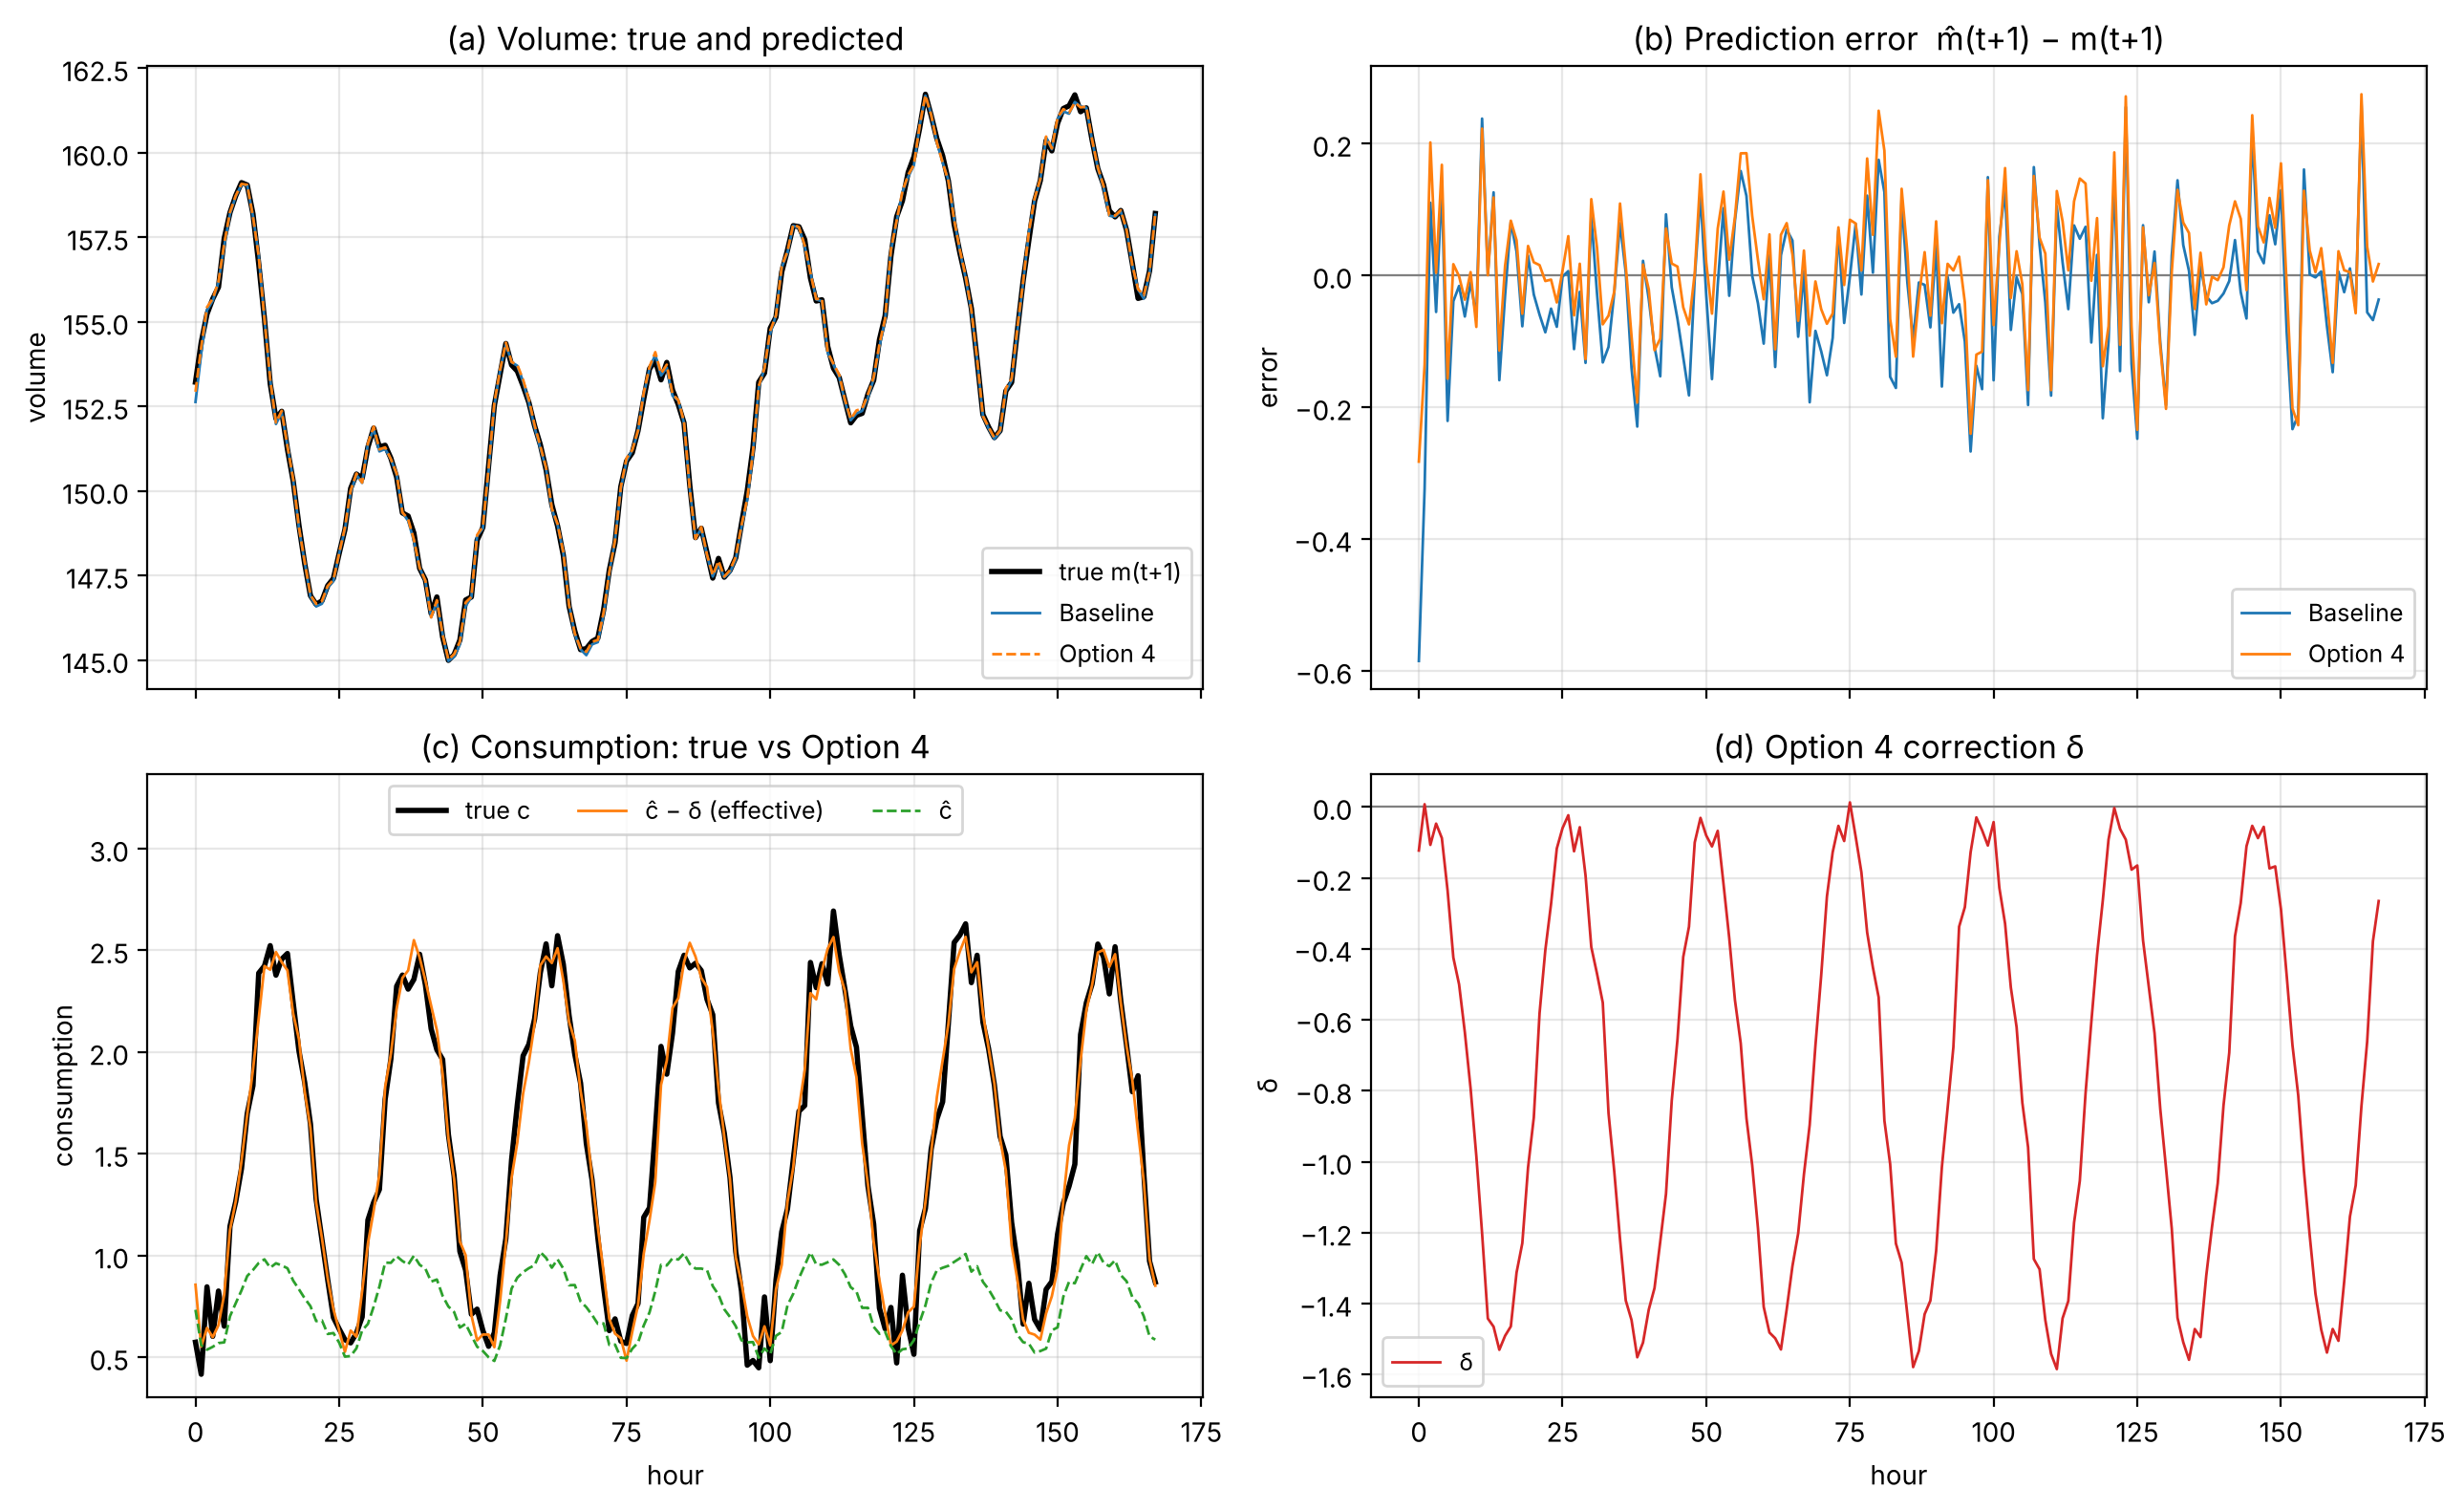

In [17]:
def plot_comparison(results, data, seq=0, hours=168):
    """Four-panel comparison of the two main models on one test sequence.

    results : {"baseline": result, "opt4": result} from run_cached
    data    : the bundle the predictions were made on; seq : test sequence; hours : steps shown
    """
    t = np.arange(hours)
    y = np.asarray(data["Y_te"][seq, :hours])
    c_true = np.asarray(data["C_te"][seq, :hours])
    m_base = results["baseline"]["test_m_pred"][seq, :hours]
    m_opt4 = results["opt4"]["test_m_pred"][seq, :hours]
    c_hat = results["opt4"]["test_c_hat"][seq, :hours]
    delta = results["opt4"]["test_delta"][seq, :hours]

    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    (a, b), (c, d) = axes

    a.plot(t, y, color="black", lw=2.0, label="true m(t+1)")
    a.plot(t, m_base, color="tab:blue", lw=1.0, label="Baseline")
    a.plot(t, m_opt4, color="tab:orange", lw=1.0, ls="--", label="Option 4")
    a.set(title="(a) Volume: true and predicted", ylabel="volume")

    b.axhline(0, color="grey", lw=0.8)
    b.plot(t, m_base - y, color="tab:blue", lw=1.0, label="Baseline")
    b.plot(t, m_opt4 - y, color="tab:orange", lw=1.0, label="Option 4")
    b.set(title="(b) Prediction error  m̂(t+1) − m(t+1)", ylabel="error")

    c.plot(t, c_true, color="black", lw=2.0, label="true c")
    c.plot(t, c_hat - delta, color="tab:orange", lw=1.0, label="ĉ − δ (effective)")
    c.plot(t, c_hat, color="tab:green", lw=1.0, ls="--", label="ĉ")
    c.set(title="(c) Consumption: true vs Option 4", ylabel="consumption", xlabel="hour")

    d.axhline(0, color="grey", lw=0.8)
    d.plot(t, delta, color="tab:red", lw=1.0, label="δ")
    d.set(title="(d) Option 4 correction δ", ylabel="δ", xlabel="hour")

    c.set_ylim(top=1.25 * max(c_true.max(), (c_hat - delta).max()))   # room for the legend
    for ax in axes.flat:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9, loc="upper center" if ax is c else "best", ncol=3 if ax is c else 1)
    plt.tight_layout()
    plt.show()
    return fig


fig = plot_comparison(RESULTS, DATA)
assert len(fig.axes) == 4
assert all(ax.get_title() and ax.get_legend() is not None for ax in fig.axes)


### Outside the training conditions: a cold spell

The two trained models predict the test sequences of `DATA_SHIFT`: the same sequences 15 °C colder, normalized with `DATA`'s statistics (no retraining). Colder weather lowers the consumption, and on some steps the clipping `max(0, ·)` sets it to exactly 0, a regime the training data never contains. The table compares each model's test MSE in distribution and on the cold spell, and its physical consistency there.

In [18]:
share_c0 = float(np.mean(np.asarray(DATA_SHIFT["C_te"]) == 0))
print(f"Cold spell: {100 * share_c0:.1f} % of test steps have c = 0 "
      f"(inputs normalized with DATA's statistics)")
print(f"True volume m(t+1): training {float(DATA['Y_tr'].min()):.1f}-{float(DATA['Y_tr'].max()):.1f}, "
      f"cold-spell test {float(DATA_SHIFT['Y_te'].min()):.1f}-{float(DATA_SHIFT['Y_te'].max()):.1f}\n")

COLD = {name: evaluate(RESULTS[name], DATA_SHIFT, prefix="shift") for name in ("baseline", "opt4")}
print(f"{'Model':10s}{'MSE in-dist':>13s}{'MSE cold':>12s}{'x worse':>10s}{'phys. cold':>13s}{'viol. cold (%)':>16s}")
for name, label in (("baseline", "Baseline"), ("opt4", "Option 4")):
    e_in, e_cold = EVAL[name], COLD[name]
    print(f"{label:10s}{e_in['mse']:>13.5f}{e_cold['mse']:>12.5g}{e_cold['mse'] / e_in['mse']:>10.3g}"
          f"{e_cold['phys']:>13.3g}{100 * e_cold['share']:>16.3f}")

assert np.array_equal(DATA_SHIFT["x_mean"], DATA["x_mean"]) and np.array_equal(DATA_SHIFT["x_std"], DATA["x_std"])
assert all(np.isfinite(v) for e in COLD.values() for v in e.values())


Cold spell: 14.4 % of test steps have c = 0 (inputs normalized with DATA's statistics)


True volume m(t+1): training 88.8-250.3, cold-spell test 149.5-568.4

Model       MSE in-dist    MSE cold   x worse   phys. cold  viol. cold (%)
Baseline        0.01529       16966  1.11e+06     0.000588           0.490
Option 4        0.01015     0.16477      16.2            0           0.000


### Interpretation of section 8

**Accuracy.** On the test set Option 4 is more accurate: MSE 0.01015 against 0.01529 (the baseline's is 1.51 times larger), MAE 0.0804 against 0.0956. Option 4's MAE of `ĉ − δ` (0.0804) is at the noise level of `c` (0.0798), so on this data it is close to the best any model could do. The baseline is not far behind; with 300 training sequences and test volumes inside the training range, a plain LSTM learns the mass well.

**Physical consistency, against the expected pattern.** The assignment expects a non-zero physical error for the baseline and, in general, for Option 4.
- The baseline does violate the balance, as expected, but rarely: physical error 2.24e-05, on 0.013 % of test steps. Nothing in its architecture prevents it; it just learned the boundary well in distribution.
- Option 4 shows **no violation on this test set** (physical error 0, 0.000 % of steps). This differs from the expected pattern, and the reason is the sign of `δ`: a violation needs `δ > ĉ`, but the learned `δ` is mostly negative (mean −0.7890), so it removes water rather than adding it. The zero is measured, not guaranteed: `δ` is unconstrained and nothing stops `δ > ĉ` on other data.

**`ĉ` and `δ`.** The expected pattern assumes `δ` is a *small* correction. Here it is not: mean |δ| 0.7903, 49 % of the mean consumption (1.5976), up to 1.7787. The loss only sees `ĉ − δ`, and the network has split the consumption between the two heads: `ĉ` alone misses the true `c` by 0.7964 on average, while `ĉ − δ` tracks it at the noise level. The comparison plot shows the pattern: `δ` is near 0 at the night minima and carries the daily peaks. So the recovered consumption is `ĉ − δ`, **not `ĉ`**. Experiment 8E.1 tests whether a penalty on `δ` separates them.

**Cost.** Option 4 has 5,058 parameters against 5,025 (two heads instead of one) and trained in 129 s against 137 s, one run each, including compilation. Wall-clock times on a shared CPU change by several seconds between executions of the same run, so this difference is noise: practically the same cost.

**Cold spell.** 15 °C colder, without retraining, the baseline's MSE grows from 0.01529 to 16966 and Option 4's from 0.01015 to 0.16477 (×16.2). This test combines two shifts. The inputs are colder, and on 14.4 % of test steps `c = 0`, a regime absent from training. And because less water is consumed, the reservoirs keep filling: the true volume reaches 568.4, against at most 250.3 in training. The baseline must produce the volume itself and cannot extrapolate that far, so most of its error comes from the volume leaving the range it learned. Option 4 takes the volume from the measurements and only has to estimate the consumption, which degrades (×16.2) but stays usable. It also keeps a zero physical error there (the baseline: 0.000588, 0.490 % of steps).

All of this comes from one seed and one kind of shift; it shows what this design does on this data, not a general ranking.

## 8E. Extended experiments

Two experiments test the two claims of the Phase A plan that matter most for Option 4. Both use the same settings as the main runs; only the factor named changes.

| Question | Experiment |
| --- | --- |
| Can `δ` be kept small, so that `ĉ` alone becomes the consumption, without losing accuracy? | **8E.1** Option 4 retrained with a penalty `μ · mean(δ²)` |
| Does the physics help more when data is scarce? | **8E.2** both models retrained with 25 to 200 training sequences |

`print_table` prints the tables of this section: one row per run, one column per quantity.

In [19]:
def print_table(rows, columns):
    """Print a table.

    rows    : list of (label, dict of values)
    columns : list of (key, header, format string), e.g. ("mse", "test MSE", "{:.5f}")
    """
    width = max(len(label) for label, _ in rows) + 2
    print(f"{'':{width}s}" + "".join(f"{h:>16s}" for _, h, _ in columns))
    for label, values in rows:
        print(f"{label:{width}s}" + "".join(f"{fmt.format(values[k]):>16s}" for k, _, fmt in columns))


### 8E.1 A penalty on δ

Section 8 showed that under the plain MSE the network splits the consumption between `ĉ` and `−δ`. Here Option 4 is retrained with

$$ L = \text{MSE} + \mu \cdot \text{mean}(\delta^2), \qquad \mu \in \{0.01, 0.1, 1.0\}, $$

which makes every unit of `δ` cost something, so the consumption should move into `ĉ`. With the main run (`μ = 0`) there are four candidates.

**Selection on validation only.** A larger `μ` is preferred (a smaller `δ` and a more interpretable `ĉ`) as long as accuracy is not lost: among the candidates whose best validation MSE is within 2 % of the lowest, the largest `μ` is chosen (Option 4-R). The test set and the true `c` play no part in the choice; they are only reported.

In [20]:
MU_RESULTS = {0.0: RESULTS["opt4"]}
for mu in CONFIG["mu_grid"]:
    MU_RESULTS[mu] = run_cached(f"opt4_mu{mu}_s112358", "option4", DATA, mu=mu)


opt4_mu0.01_s112358: loaded from cache
opt4_mu0.1_s112358: loaded from cache
opt4_mu1.0_s112358: loaded from cache


**Selection and results.** `select_mu` applies the rule above to the best validation MSE of each run. The table then reports, for every `μ`, the validation and test MSE, the physical error and violation share, the size of `δ`, and how well `ĉ` and `ĉ − δ` recover the true `c` (test set).

In [21]:
def select_mu(val_mse, tolerance=0.02):
    """Choose mu on validation: the largest mu whose validation MSE is within tolerance of the lowest.

    val_mse : {mu: best validation MSE of that run}
    Returns (chosen mu, threshold = (1 + tolerance) * lowest validation MSE).
    """
    threshold = (1 + tolerance) * min(val_mse.values())
    return max(mu for mu, v in val_mse.items() if v <= threshold), threshold


val_mse = {mu: float(np.min(res["val_loss"])) for mu, res in MU_RESULTS.items()}
MU_CHOSEN, threshold = select_mu(val_mse)

mu_rows = []
for mu, res in MU_RESULTS.items():
    values = {"val": val_mse[mu], **evaluate(res, DATA)}
    mu_rows.append((f"mu = {mu}" + ("  (chosen)" if mu == MU_CHOSEN else ""), values))
print_table(mu_rows, [("val", "val. MSE", "{:.5f}"), ("mse", "test MSE", "{:.5f}"),
                      ("phys", "phys. error", "{:.3g}"), ("share", "viol. share", "{:.4%}"),
                      ("mean_abs_delta", "mean |delta|", "{:.4f}"), ("mean_delta", "mean delta", "{:+.4f}"),
                      ("mae_c", "MAE c_hat", "{:.4f}"), ("mae_eff", "MAE c_hat-delta", "{:.4f}")])
print(f"\nRule: largest mu with validation MSE <= (1 + 0.02) x lowest = {threshold:.5f}  ->  chosen mu = {MU_CHOSEN}")

assert len(MU_RESULTS) == 4 and sorted(MU_RESULTS) == [0.0] + CONFIG["mu_grid"]
assert MU_CHOSEN == select_mu({mu: float(np.min(r["val_loss"])) for mu, r in MU_RESULTS.items()})[0]  # validation only
assert all(np.isfinite(v) for _, row in mu_rows for v in row.values())


                            val. MSE        test MSE     phys. error     viol. share    mean |delta|      mean delta       MAE c_hat MAE c_hat-delta
mu = 0.0                     0.00992         0.01015               0         0.0000%          0.7903         -0.7890          0.7964          0.0804
mu = 0.01                    0.00994         0.01015               0         0.0000%          0.0217         -0.0031          0.0844          0.0804
mu = 0.1                     0.00992         0.01015               0         0.0000%          0.0059         -0.0010          0.0808          0.0804
mu = 1.0  (chosen)           0.00991         0.01013               0         0.0000%          0.0018         +0.0004          0.0803          0.0803

Rule: largest mu with validation MSE <= (1 + 0.02) x lowest = 0.01010  ->  chosen mu = 1.0


**Plot.** `ĉ` alone against the true consumption on the same week as section 8, for the main run (`μ = 0`) and the chosen `μ`. If the penalty works, the chosen run's `ĉ` should follow the true `c`, without needing `δ`.

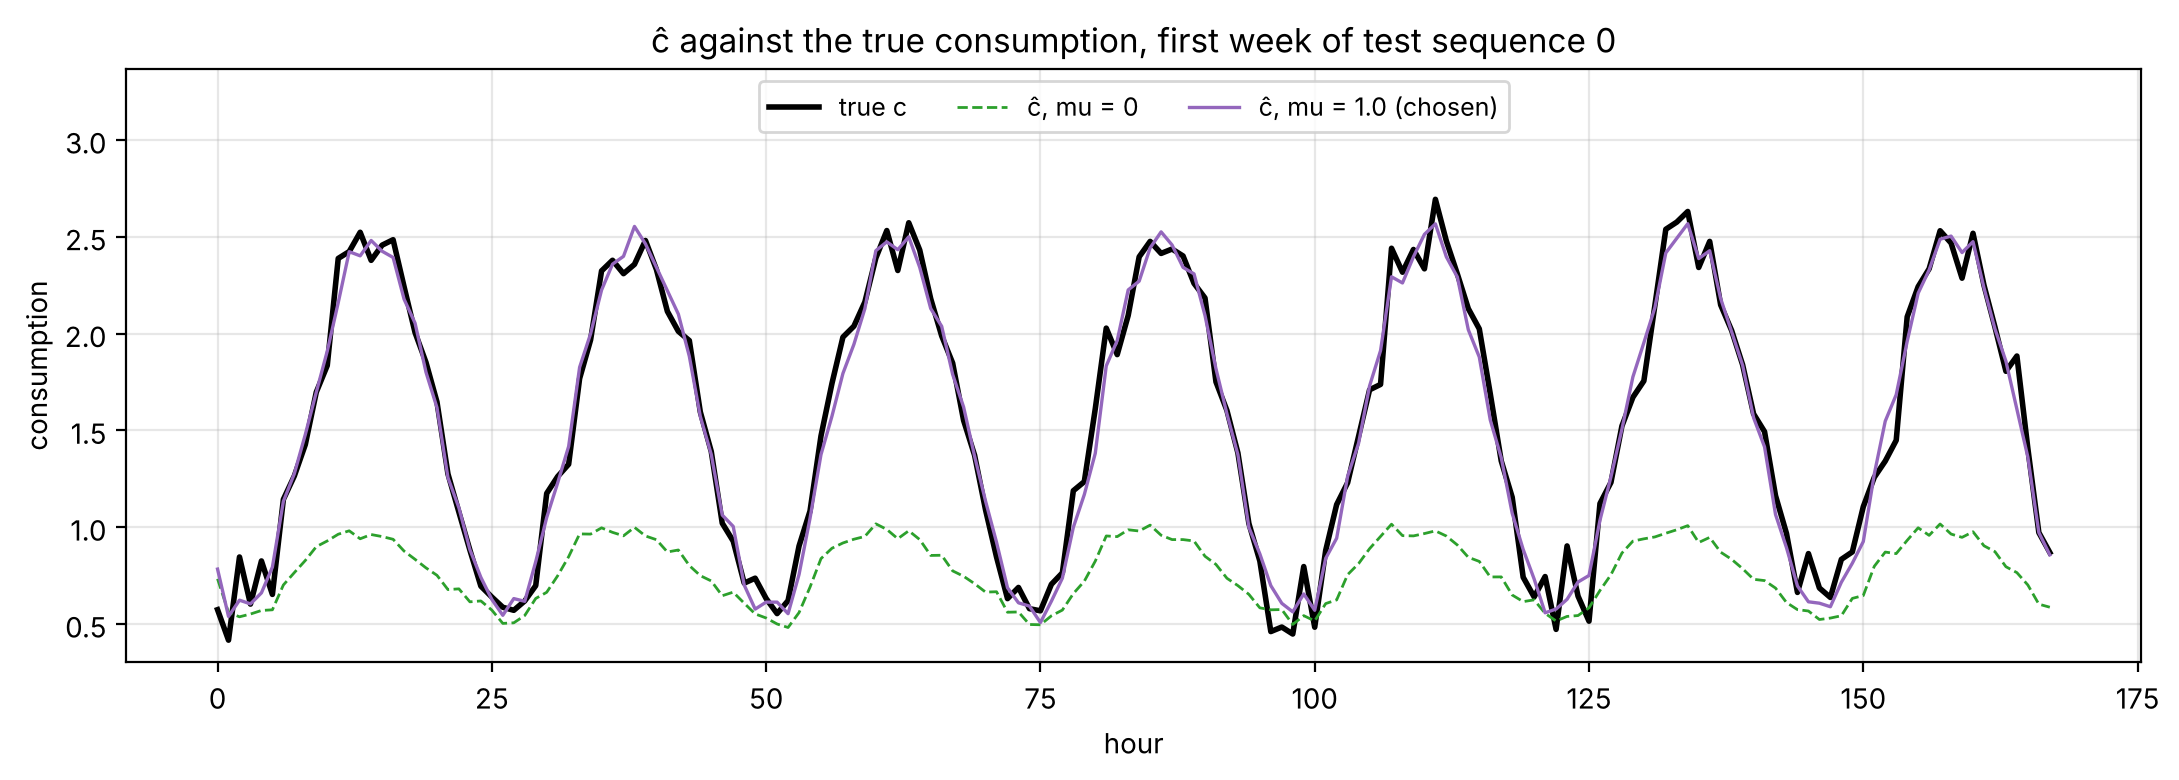

In [22]:
t = np.arange(168)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, np.asarray(DATA["C_te"][0, :168]), color="black", lw=2.0, label="true c")
ax.plot(t, MU_RESULTS[0.0]["test_c_hat"][0, :168], color="tab:green", lw=1.0, ls="--", label="ĉ, mu = 0")
ax.plot(t, MU_RESULTS[MU_CHOSEN]["test_c_hat"][0, :168], color="tab:purple", lw=1.2,
        label=f"ĉ, mu = {MU_CHOSEN} (chosen)")
ax.set(title="ĉ against the true consumption, first week of test sequence 0",
       xlabel="hour", ylabel="consumption")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="upper center", ncol=3)
ax.set_ylim(top=1.25 * float(DATA["C_te"][0, :168].max()))
plt.tight_layout()
plt.show()


**Interpretation of 8E.1.**

- **The penalty separates `ĉ` from `δ`.** Even the smallest weight makes `δ` almost vanish: mean |δ| falls from 0.7903 (`μ = 0`) to 0.0217, 0.0059 and 0.0018 for `μ` = 0.01, 0.1 and 1.0. The consumption moves into `ĉ`: the MAE of `ĉ` alone drops from 0.7964 to 0.0844, 0.0808 and 0.0803, the same level as the effective consumption `ĉ − δ` (0.0803–0.0804). In the plot, the chosen run's `ĉ` follows the true `c`, while the main run's `ĉ` only follows its lower part.
- **No accuracy is lost.** The four candidates' validation MSEs differ only in the fourth significant digit (0.00991–0.00994), well under the threshold 0.01010, so the rule picks the largest weight, **`μ = 1.0`** (Option 4-R). Its test MSE, 0.01013, equals the main run's 0.01015 for practical purposes, and every run keeps a zero physical error.
- **Why it costs nothing here.** Under the plain MSE, `ĉ` and `−δ` are interchangeable: any split with the same `ĉ − δ` gives the same prediction, so the split is arbitrary. The penalty only breaks that tie. It is free in this simulation because the balance is complete, so `δ` has nothing real to absorb. If the balance missed a real flow (the case Option 4 was chosen for in Phase A), the penalty would compete with accuracy, and the validation rule would then choose a smaller `μ`. This was not tested here.
- **For the Phase A plan:** `δ` does **not** stay small by itself (main run), but a light penalty, chosen on validation, makes it small and gives an interpretable `ĉ` at no cost in accuracy. One seed; the selection differences are tiny compared with what a change of seed could produce.

### 8E.2 Low-data ablation

Phase A expected the physics to matter most when data is scarce: Option 4 only has to learn the consumption, while the baseline must also learn the mass. Both models are retrained with `n_train` = 25, 50, 100 and 200 training sequences (the first ones of the training split); the main runs give the point at 300. Everything else is fixed: the same validation and test sequences, the same settings, and normalization statistics computed from the training sequences actually used (so the baseline's output scaling also comes from them). No cold-spell predictions here.

In [23]:
LOW_DATA = {n: make_dataset(data_key, n_train=n, tag=f"n{n}") for n in CONFIG["n_train_grid"]}
LOW_DATA[CONFIG["n_train"]] = DATA
LOW_RESULTS = {"baseline": {CONFIG["n_train"]: RESULTS["baseline"]}, "opt4": {CONFIG["n_train"]: RESULTS["opt4"]}}
for n in CONFIG["n_train_grid"]:
    for label, kind in (("baseline", "baseline"), ("opt4", "option4")):
        LOW_RESULTS[label][n] = run_cached(f"{label}_n{n}_s112358", kind, LOW_DATA[n])


baseline_n25_s112358: loaded from cache
opt4_n25_s112358: loaded from cache
baseline_n50_s112358: loaded from cache
opt4_n50_s112358: loaded from cache
baseline_n100_s112358: loaded from cache
opt4_n100_s112358: loaded from cache
baseline_n200_s112358: loaded from cache
opt4_n200_s112358: loaded from cache


**Results.** For each training-set size: the test MSE of both models and their ratio (baseline / Option 4), and the violation share and physical error of both. All on the same 100 test sequences.

In [24]:
N_SIZES = sorted(LOW_DATA)
LOW_EVAL = {label: {n: evaluate(LOW_RESULTS[label][n], LOW_DATA[n]) for n in N_SIZES}
            for label in ("baseline", "opt4")}
low_rows = []
for n in N_SIZES:
    b, o = LOW_EVAL["baseline"][n], LOW_EVAL["opt4"][n]
    low_rows.append((f"n_train = {n}", {"mse_b": b["mse"], "mse_o": o["mse"], "ratio": b["mse"] / o["mse"],
                                        "share_b": b["share"], "share_o": o["share"],
                                        "phys_b": b["phys"], "phys_o": o["phys"]}))
print_table(low_rows, [("mse_b", "MSE baseline", "{:.5f}"), ("mse_o", "MSE Option 4", "{:.5f}"),
                       ("ratio", "ratio B / O4", "{:.2f}"), ("share_b", "viol. baseline", "{:.3%}"),
                       ("share_o", "viol. Option 4", "{:.3%}"), ("phys_b", "phys. baseline", "{:.3g}"),
                       ("phys_o", "phys. Option 4", "{:.3g}")])

assert all(len(LOW_EVAL[label]) == 5 for label in LOW_EVAL)
for n in N_SIZES:
    for k in ("X_va", "Y_va", "X_te", "Y_te"):
        assert bool(jnp.all(LOW_DATA[n][k] == DATA[k]))          # same validation and test sets
    assert LOW_DATA[n]["X_tr"].shape[0] == n
assert all(np.isfinite(v) for _, row in low_rows for v in row.values())


                   MSE baseline    MSE Option 4    ratio B / O4  viol. baseline  viol. Option 4  phys. baseline  phys. Option 4
n_train = 25            6.30048         0.01379          456.74          6.196%          0.000%           0.335               0
n_train = 50            0.21744         0.01108           19.63          0.535%          0.000%           0.016               0
n_train = 100           0.03962         0.01040            3.81          0.179%          0.000%           0.002               0
n_train = 200           0.02204         0.01025            2.15          0.077%          0.000%         0.00083               0
n_train = 300           0.01529         0.01015            1.51          0.013%          0.000%        2.24e-05               0


**Plots.** Left: test MSE against the number of training sequences, both axes logarithmic, with the noise floor 0.01 (the variance of the unpredictable part of `c`) as a reference. Right: the share of test steps whose implied consumption is negative.

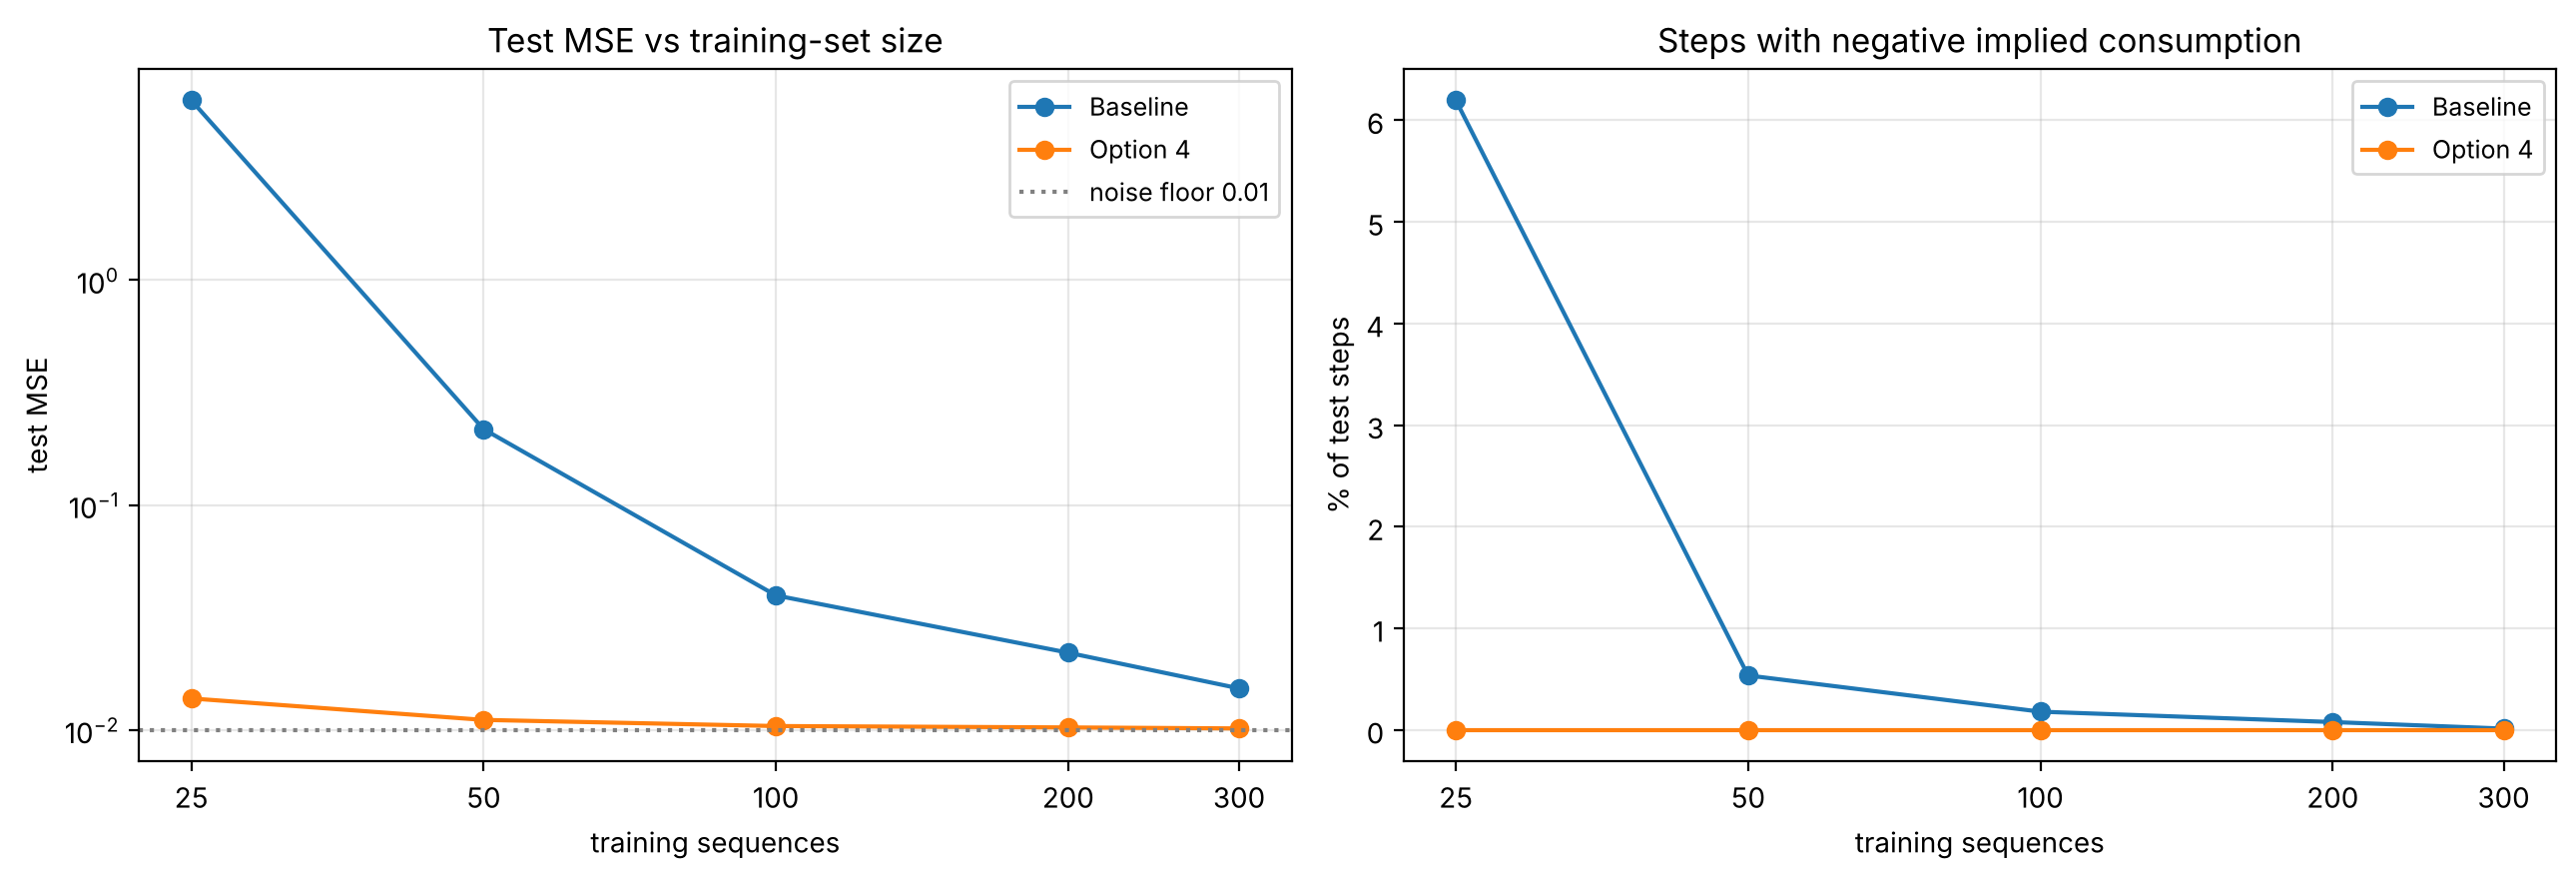

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for label, name, color in (("baseline", "Baseline", "tab:blue"), ("opt4", "Option 4", "tab:orange")):
    ax1.plot(N_SIZES, [LOW_EVAL[label][n]["mse"] for n in N_SIZES], "o-", color=color, label=name)
    ax2.plot(N_SIZES, [100 * LOW_EVAL[label][n]["share"] for n in N_SIZES], "o-", color=color, label=name)
ax1.axhline(0.01, color="grey", ls=":", label="noise floor 0.01")
ax1.set(xscale="log", yscale="log", title="Test MSE vs training-set size",
        xlabel="training sequences", ylabel="test MSE")
ax2.set(xscale="log", title="Steps with negative implied consumption",
        xlabel="training sequences", ylabel="% of test steps")
for ax in (ax1, ax2):
    ax.set_xticks(N_SIZES)
    ax.set_xticklabels([str(n) for n in N_SIZES])
    ax.minorticks_off()
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


**Interpretation of 8E.2.**

- **Option 4 barely needs data.** Its test MSE is 0.01379 with only 25 training sequences and 0.01015 with 300: already close to the noise floor 0.01 at the smallest size. The balance gives it the mass; the consumption it has to learn is a smooth function of temperature and hour, which 25 sequences of 480 hours already describe well.
- **The baseline does.** Its test MSE falls by more than two orders of magnitude, from 6.30048 at 25 sequences to 0.01529 at 300, and is still above Option 4's at every size. The ratio baseline / Option 4 shrinks with data: 456.74, 19.63, 3.81, 2.15 and 1.51. The physics helps most where data is scarcest, as Phase A expected, and its advantage in accuracy narrows as data grows.
- **Physical consistency follows the same pattern.** The baseline implies negative consumption on 6.196 % of test steps with 25 sequences (physical error 0.335), and on fewer as data grows, down to 0.013 % at 300, but never on none. Option 4 shows 0.000 % at every size. That zero is measured, not guaranteed, for the reason given in section 8 (`δ` mostly negative here).
- **Scope.** One seed per point: each size uses one particular set of training sequences and one initialization, so the baseline's values at small sizes in particular could move with another seed. The direction of the effect and its size at 25 sequences (a ratio of 456.74) are large enough not to depend on those details.

<a id='10'></a>
## 9. Reflection questions

Answer using evidence from **your own** experiments — refer to your metrics table and plots, not just general reasoning.

**1. Why can a conventional LSTM violate a physical law, even after being trained to convergence on plenty of data?**

**Notes for question 1**

- The MSE only measures the distance to the target. A prediction above `m + r − q` (impossible) and one below it (possible) at the same distance get the same loss, so training never pushes the model towards the physical side (Phase A, Discussion 2).
- The law `m̂(t+1) ≤ m(t) + r(t) − q(t)` appears nowhere in the baseline's architecture or loss. The network can only approximate the boundary from examples, so near it (small `c`) a small error crosses it.
- Evidence after convergence on the most data used here (300 sequences, best epoch 241 of 300, section 7): the baseline still implies negative consumption on 0.013 % of test steps, physical error 2.24e-05 (section 8). Rare, but not zero.
- More data reduces violations but does not remove them: 6.196 % of test steps with 25 sequences, 0.013 % with 300 (8E.2).
- Outside the training conditions nothing holds it: on the cold spell, 0.490 % of steps violate the balance (physical error 0.000588), and its volume predictions cannot follow true volumes up to 568.4 when training never went above 250.3 (section 8).

_Your answer:_

The conventional LSTM has the only job of predicting the next value m̂(t+1), considering only how far it lands from the target. Every prediction carries a possible error, and the physical limit is m(t) + r(t) − q(t), the value the reservoir would reach if nothing were consumed. When the true consumption is small, the target sits right next to that limit, and the aforementioned error can situate the prediction above it, at a value which would imply a negative consumption. The MSE loss treats an error above the target the same as one below it, so training only makes the errors smaller; it never teaches the model which side is impossible.

In our results the baseline, trained to its best epoch on 300 sequences, still implies a negative consumption on 0.021 % of the test steps, rising to 6.177 % with 25 training sequences and to 0.15 % on the cold-spell test set. Adding a failsafe to the architecture prevents this issue: Option 4 predicts the consumption through a softplus, so its estimate can never be negative, and computes the next value from the balance. Its correction δ is not restricted, so the protection is not complete, but in our runs it never implied a negative consumption.

**2. What is the difference between a soft constraint and a hard constraint? If you implemented Option 3 or 4, where would a soft constraint have gone instead, and how would training/evaluation have differed? If you implemented Option 2, reflect on how your choice of `λ` affected the accuracy/conservation trade-off.**

**Notes for question 2**

- **Soft constraint:** the law is a penalty in the loss, traded against accuracy through a weight. It is encouraged, never guaranteed; it holds only approximately and only where training data pushed it.
- **Hard constraint:** the law is part of the architecture, so it holds for every output, before training and on any input (Option 3: `m̂ = m + r − q − ĉ`, `ĉ = softplus(·) ≥ 0`).
- **Option 4 is in between.** The balance is hard-wired, but `δ` is unconstrained, so conservation is not guaranteed. Here no violation was measured (physical error 0, section 8) because the learned `δ` is mostly negative (mean −0.7890), not because the architecture forbids it.
- **Where a soft constraint would have gone (Option 2):** two free heads `(m̂, ĉ)` and an extra loss term `λ · (m̂ − m − r + q + ĉ)²`. Training: a new hyperparameter `λ`, chosen on validation with several runs. Evaluation: the physical error would generally be non-zero, and a larger `λ` would trade accuracy for consistency.
- **This notebook did use a soft term, on top of the hard structure:** 8E.1's `μ · mean(δ²)` is a soft constraint on `δ`. It needed a grid of 3 extra runs and a validation rule, exactly what Option 2's `λ` would need. With `μ = 1.0`, mean |δ| fell from 0.7903 to 0.0018 while the test MSE stayed at 0.01013 (0.01015 without it).

_Your answer:_

*(write here)*

**3. How does physical knowledge act as an inductive bias? Explain how you would test this claim with the optional low-data ablation described in the assignment, and connect it to your own results if you ran it.**

**Notes for question 3**

- **Inductive bias:** assumptions built into a model that restrict which functions it can represent or prefers. The balance in Option 4 gives the large, known part of the prediction (`m + r − q`, values around 156) for free; the network only learns the small unknown part (`ĉ − δ`, around 1–2).
- **Seen from the start of training (section 7):** Option 4's first-epoch training loss is 0.5097 against 213 for the baseline.
- **How to test it (8E.2):** retrain both models with fewer training sequences (25, 50, 100, 200, plus 300), keeping everything else fixed: same validation and test sets, same settings, statistics from the sequences used. If the physics is a useful bias, Option 4 should degrade much less as data shrinks.
- **Result (8E.2):** with 25 sequences Option 4's test MSE is 0.01379, already near the noise floor 0.01, while the baseline's is 6.30048: a ratio of 456.74. The ratio shrinks to 1.51 at 300 sequences. The baseline also violates the balance on 6.196 % of test steps at 25 sequences; Option 4 on none, at every size.
- **Reading:** the bias substitutes for data. Its advantage is largest when data is scarce and narrows (in accuracy) as data grows. One seed per point; the effect at 25 sequences is far larger than seed noise would plausibly explain.

_Your answer:_

*(write here)*

**4. In what other application domains could this idea (predicting an unknown residual term and reconstructing the target analytically) be useful? Give at least one concrete example outside of hydrology.**

**Notes for question 4**

- **The common pattern:** a quantity follows a known balance or identity with one unknown term; the network predicts only that term, and the quantity is reconstructed analytically.
- **Battery state of charge:** charge(t+1) = charge(t) + charged − discharged − losses; the network predicts the losses (temperature, age, current), the identity keeps the charge consistent.
- **Building heat balance:** next indoor temperature from heating input, outdoor exchange and an unknown internal gain (occupants, appliances) learned by the network.
- **Inventory / supply chain:** stock(t+1) = stock(t) + deliveries − recorded sales − unknown shrinkage (losses, theft, errors), the last term learned.
- **Epidemiology (compartment models):** the population is conserved across compartments (S + I + R constant); the network learns the transmission or recovery rates, the flows between compartments are computed.
- **Chemical reactors:** species and mass balances with learned reaction rates.
- **A caveat from this notebook (section 8, 8E.1):** if two learned terms enter only through their difference (here `ĉ` and `δ`), the data cannot separate them. `ĉ` alone was off by 0.7964 under the plain loss and recovered to 0.0803 only with a penalty on `δ`. The same care applies in any domain with more than one learned residual.

_Your answer:_

*(write here)*

**5. How could causality, rather than mass conservation, be incorporated into a neural network architecture? What would "hard enforcement" of a causal constraint even mean, compared to enforcing a conservation law?**

**Notes for question 5**

- **Causality in time is already hard-enforced here:** the LSTM's hidden state at step `t` depends only on inputs up to `t` (section 5), so no prediction can use the future. That is a structural guarantee, like a causal mask in a transformer.
- **Causal structure between variables:** if a causal graph is known (e.g. temperature and hour → consumption, never the reverse), each learned function can receive **only its causal parents** as inputs, by architecture (separate sub-networks, masked weights). That is the analogue of hard enforcement: the model cannot represent a dependence the graph forbids.
- **Other partial forms:** monotonicity (consumption rises with temperature) through monotone networks or constrained weights; invariance of a mechanism across environments as a training objective (a soft constraint).
- **Why "hard" means something different:** conservation is an equality that can be checked on every single output (`m̂ = m + r − q − ĉ`). A causal claim is about what **would** happen under an intervention, `do(temperature = x)`, so it cannot be verified from observed outputs alone. Enforcing the input structure guarantees the model's own dependencies, not that they match reality.
- **The guarantee is only as good as the assumed graph:** a wrong graph is enforced just as strictly as a right one, and the graph generally cannot be learned from observational data alone. With conservation the law itself is certain; the uncertainty is only in the unknown term.

_Your answer:_

*(write here)*

<a id='11'></a>
## 11. Before you submit

**Common pitfalls to double-check:**
- The true `c(t)` never leaks into either model's inputs.
- Train/test split is by *sequence*, not by timestep.
- Normalization statistics come from the training split only.
- Your model's mass computation (Options 3/4) or physics loss term (Option 2) uses raw, unnormalized `m, r, q`.
- Both models used the same hidden size, optimizer, learning rate, epochs, and batch size.
- You didn't reuse a JAX PRNG key without splitting it first.


**Final checks.** The cell below verifies the pitfalls above on every training run of this notebook, reading each result back from `results/`.

In [26]:
BUNDLES = {"main": DATA, "shift": DATA_SHIFT, **{f"n{n}": LOW_DATA[n] for n in CONFIG["n_train_grid"]}}
STORED = {name: dict(np.load(os.path.join("results", f"{name}.npz"))) for name in RUNS}
used_tags = {info["tag"] for info in RUNS.values()} | {"shift"}

# 1. c(t) never enters the models: six input features; a batch built as in train_model holds only xn, x, y
batch = make_batch(DATA["Xn_tr"], {"x": DATA["X_tr"]}, DATA["Y_tr"], jnp.arange(BATCH_SIZE))
assert set(batch) == {"xn", "x", "y"}
assert all(BUNDLES[t][f"{k}_{s}"].shape[-1] == 6 for t in used_tags for k in ("X", "Xn") for s in ("tr", "va", "te"))
print("✓ 1. c(t) never enters the models: 6 input features, batches hold only xn, x, y")

# 2. Train, validation and test share no sequence (a sequence is identified by its first 5 volumes)
for t in used_tags:
    ids = [seq_ids(BUNDLES[t][f"X_{s}"]) for s in ("tr", "va", "te")]
    assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2])
print("✓ 2. Train, validation and test share no sequence")

# 3. Statistics from each bundle's own training split; DATA_SHIFT reuses DATA's
for t in used_tags - {"shift"}:
    x_tr = np.asarray(BUNDLES[t]["X_tr"], np.float64)
    assert np.allclose(BUNDLES[t]["x_mean"], x_tr.mean(axis=(0, 1)))
    assert np.allclose(BUNDLES[t]["x_std"], x_tr.std(axis=(0, 1)))
    assert np.isclose(BUNDLES[t]["y_mean"], np.asarray(BUNDLES[t]["Y_tr"], np.float64).mean())
assert all(np.array_equal(DATA_SHIFT[k], DATA[k]) for k in ("x_mean", "x_std")) and DATA_SHIFT["y_mean"] == DATA["y_mean"]
print("✓ 3. Normalization statistics come from the training split")

# 4. Identical settings: 300 epochs everywhere, the expected parameter count, mu > 0 only in 8E.1
expected_params = {"baseline": 5025, "option4": 5058}
for name, info in RUNS.items():
    assert len(STORED[name]["train_loss"]) == len(STORED[name]["val_loss"]) == CONFIG["epochs"]
    assert int(STORED[name]["n_params"]) == expected_params[info["kind"]]
    assert (info["mu"] > 0) == name.startswith("opt4_mu")
print(f"✓ 4. All {len(RUNS)} runs used the same settings ({CONFIG['epochs']} epochs; μ > 0 only in 8E.1)")

# 5. Raw units in the balance: stored predictions of opt4_s112358 equal ((m + r) - q) - c_hat + delta
s = STORED["opt4_s112358"]
X_te = np.asarray(DATA["X_te"])
balance = ((X_te[..., 0] + X_te[..., 1]) - X_te[..., 2]) - s["test_c_hat"] + s["test_delta"]
assert np.max(np.abs(s["test_m_pred"] - balance)) < 1e-3
print("✓ 5. Option 4's balance uses raw physical units")

# 6. Every run has its own PRNG key (and none equals the data key)
keys = {tuple(np.asarray(run_key(name, info["seed"])).tolist()) for name, info in RUNS.items()}
assert len(keys) == len(RUNS) and tuple(np.asarray(data_key).tolist()) not in keys
print("✓ 6. Every run has its own random key")

print("All 6 checks passed.")


✓ 1. c(t) never enters the models: 6 input features, batches hold only xn, x, y
✓ 2. Train, validation and test share no sequence
✓ 3. Normalization statistics come from the training split
✓ 4. All 13 runs used the same settings (300 epochs; μ > 0 only in 8E.1)
✓ 5. Option 4's balance uses raw physical units
✓ 6. Every run has its own random key
All 6 checks passed.


**Deliverables checklist:**
- [x] Reproducible notebook, seeded end-to-end with explicit `PRNGKey`s
- [x] Synthetic data generator with a sanity-check plot of at least one simulated sequence
- [x] Baseline LSTM implementation (Option 1)
- [x] Your chosen model implementation (Option 2, 3, or 4 -- matching your Phase A plan)
- [x] Both models trained under identical settings, with training-loss curves plotted together
- [x] Metrics table (MSE, MAE, physical error, training time) on the test set for both models
- [x] *(recommended, optional bonus)* Low-data ablation plot (test MSE vs. training-set size)
- [ ] Written answers to all five reflection questions, grounded in your own results